In [30]:
import sys, torch
print(sys.executable)
print(torch.cuda.is_available())

c:\TCC\venv\Scripts\python.exe
True


In [38]:
ibovespa = ibov_raw[("Close", "^BVSP")].reset_index()
ibovespa.columns = ["date", "ibovespa"]

vix = vix_raw[("Close", "^VIX")].reset_index()
vix.columns = ["date", "vix"]

# Previsão One Step Ahead

### Função de split

In [ ]:
def split_temporal(database, train_frac=0.8):
    n = len(database)
    cut = int(n * train_frac)
    return database.iloc[:cut], database.iloc[cut:]

# ARIMA

In [ ]:
pip install pmdarima

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 688.9/688.9 kB 11.6 MB/s eta 0:00:00


In [ ]:
from statsmodels.tsa.arima.model import ARIMA
from pmdarima import auto_arima
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

## VALE3

In [ ]:
# --- Corte único, usado como referência pelos 3 modelos ---
train_vale, test_vale = split_temporal(dataset_vale, train_frac=0.8)
cut_date = test_vale.index[0]

In [ ]:
train_vale = train_vale.set_index(pd.to_datetime(train_vale['date'])).drop(columns=['index'], errors='ignore')
test_vale = test_vale.set_index(pd.to_datetime(test_vale['date'])).drop(columns=['index'], errors='ignore')

In [ ]:
# 1. auto_arima encontra a melhor ordem (p, d, q) no TREINO
print('--- Identificando Ordem do ARIMA Básico ---')
modelo_auto = auto_arima(
    train_vale['vale_close'],
    seasonal=False,
    trace=True,
    suppress_warnings=True,
)
ordem = modelo_auto.order
print(f'Ordem ARIMA Selecionada: {ordem}')

# 2. Treina o modelo inicial no conjunto de TREINO
modelo_treinado = ARIMA(train_vale['vale_close'], order=ordem).fit()

# 3. Walk-Forward Simulation no TESTE:
# O método .apply() estende a estrutura do modelo ao conjunto de TESTE,
# fazendo previsões de 1 passo à frente (one-step-ahead) usando os preços reais passados.
modelo_expandido = modelo_treinado.apply(test_vale['vale_close'])

# Obter as previsões ajustadas para o período de teste
previsoes_arima = modelo_expandido.fittedvalues

# 4. Avaliação justa das métricas
y_test = test_vale['vale_close']
rmse_arima = np.sqrt(mean_squared_error(y_test, previsoes_arima))
mape_arima = mean_absolute_percentage_error(y_test, previsoes_arima)

print(f'\n--- Resultados do ARIMA Básico (One-Step Ahead) ---')
print(f'RMSE: {rmse_arima:.4f}')
print(f'MAPE: {mape_arima:.2%}')

--- Identificando Ordem do ARIMA Básico ---
Performing stepwise search to minimize aic
 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=6245.397, Time=11.09 sec
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=6241.633, Time=0.56 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=6243.557, Time=0.47 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=6243.555, Time=1.28 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=6240.426, Time=0.21 sec
 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=6243.876, Time=5.94 sec

Best model:  ARIMA(0,1,0)(0,0,0)[0]          
Total fit time: 19.600 seconds
Ordem ARIMA Selecionada: (0, 1, 0)

--- Resultados do ARIMA Básico (One-Step Ahead) ---
RMSE: 2.0255
MAPE: 1.27%


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, fr

In [ ]:
acerto_direcional = np.mean(np.sign(y_test.diff()) == np.sign(previsoes_arima.diff()))
print(f'Acurácia direcional: {acerto_direcional:.2%}')...d.infp....kuashd..........sjdssdasdsdasd

Acurácia direcional: 52.20%


In [ ]:
# Valores reais e previstos
y_true = test_vale['vale_close']
y_pred = previsoes_arima

# Métricas de erro
mae = mean_absolute_error(y_true, y_pred)
rmse = np.sqrt(mean_squared_error(y_true, y_pred))
mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100

print(f"MAE (Erro Médio Absoluto): {mae:.2f}")
print(f"RMSE (Raiz do Erro Quadrático Médio): {rmse:.2f}")
print(f"MAPE (Erro Percentual Absoluto Médio): {mape:.2f}%")

MAE (Erro Médio Absoluto): 0.67
RMSE (Raiz do Erro Quadrático Médio): 2.03
MAPE (Erro Percentual Absoluto Médio): 1.27%


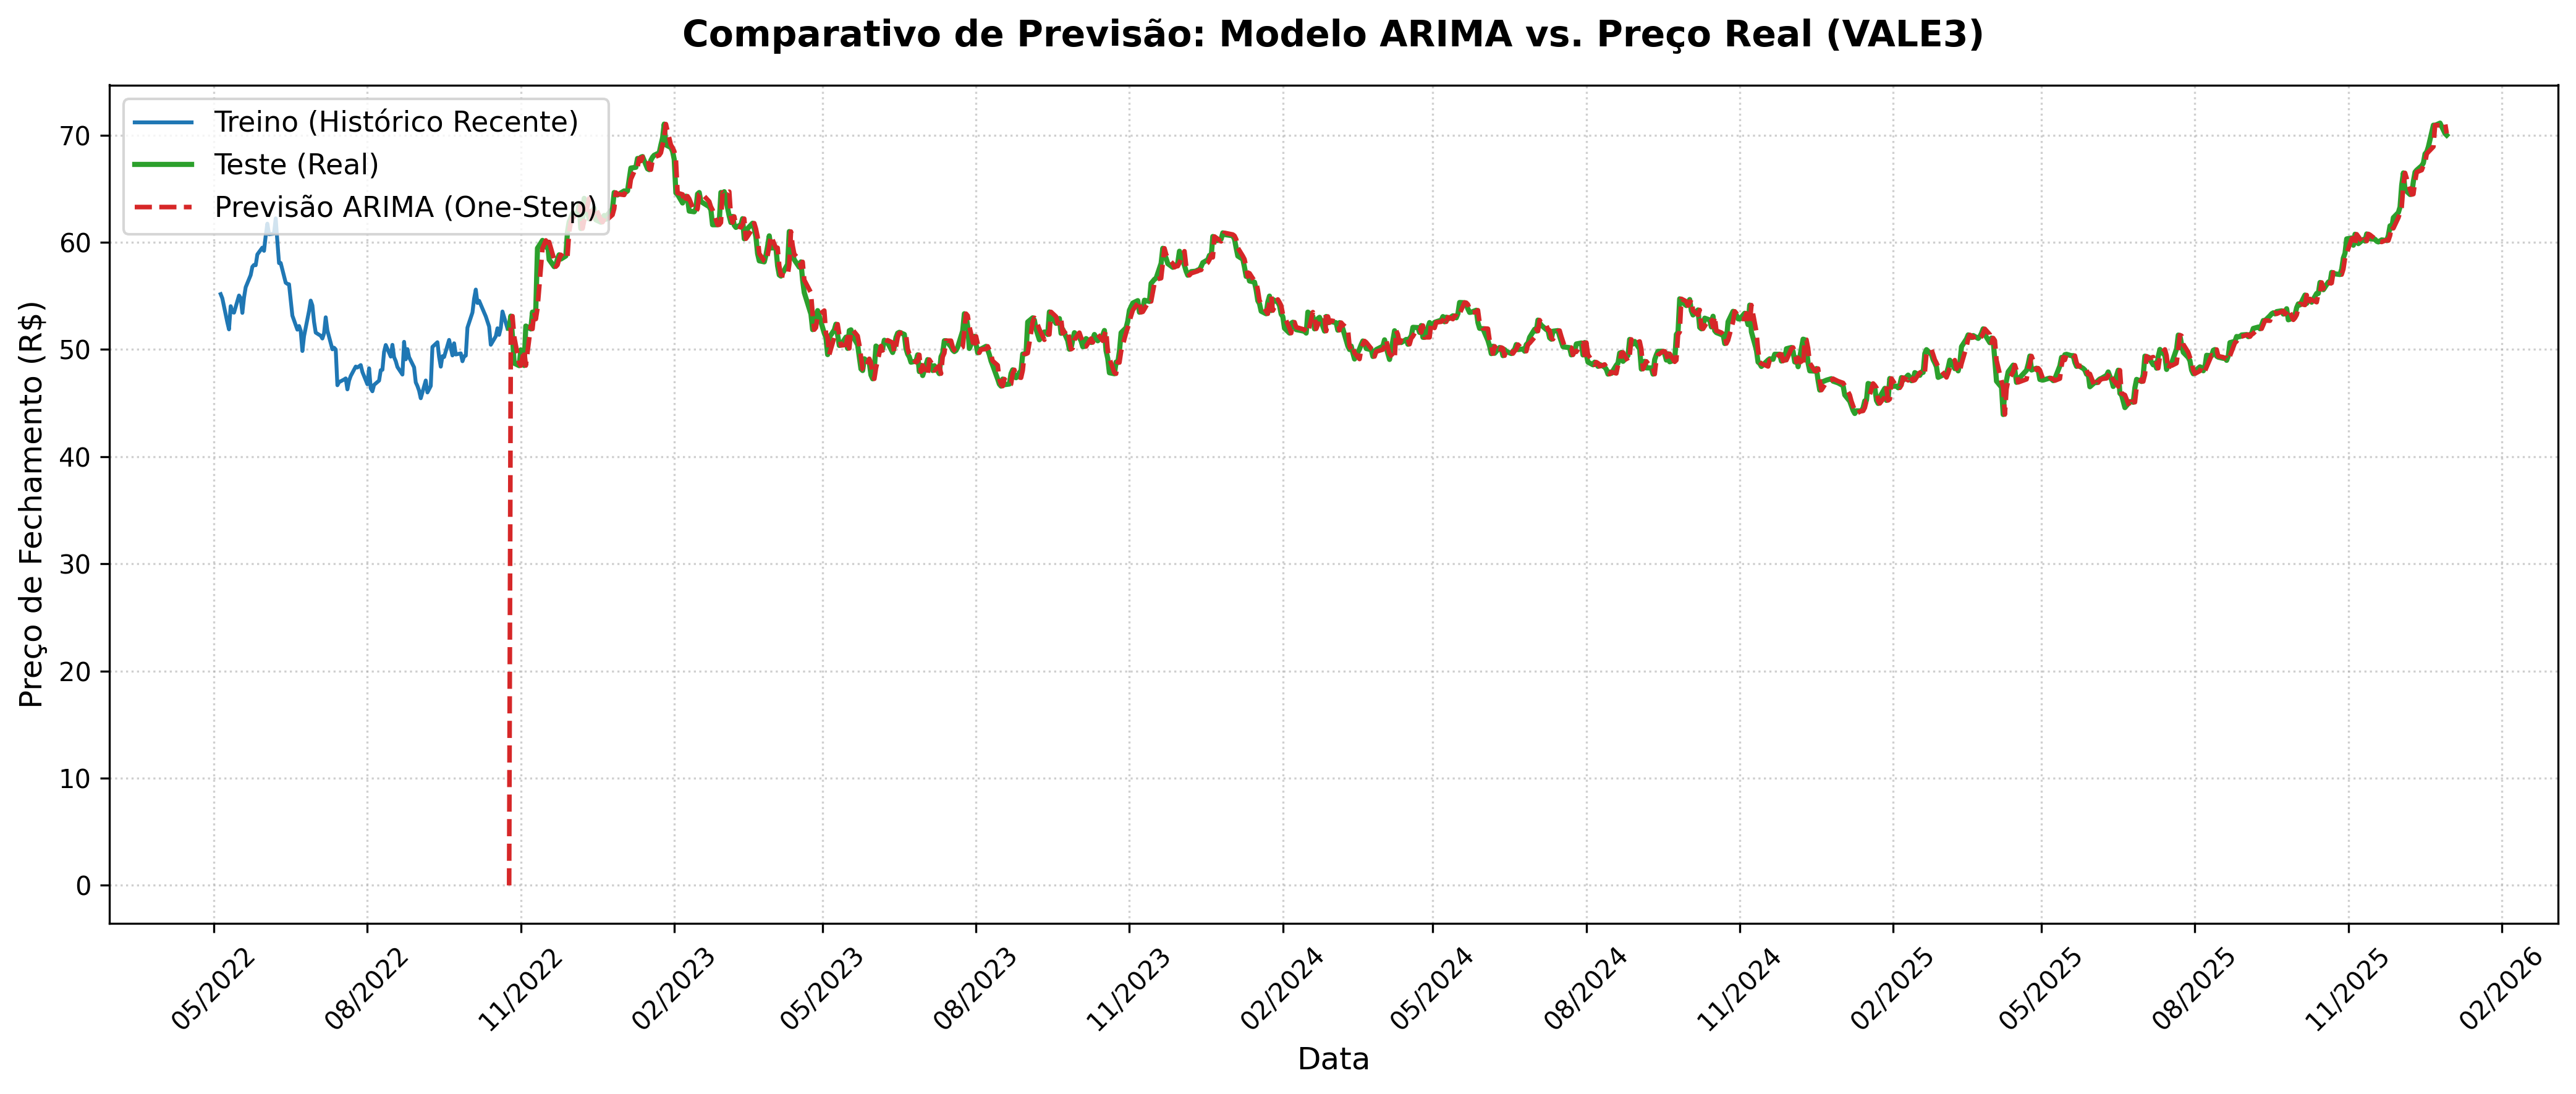

In [ ]:
# Definir o zoom: mostra apenas o final do treino para não 'apertar' a visualização do teste
zoom_treino = train_vale.iloc[-120:]  # Últimos ~6 meses de treino (120 dias úteis)

plt.figure(figsize=(14, 6), dpi=300)  # Resolução alta para exportar ao Word/LaTeX

# 1. Dados Históricos (Treino Recente e Teste Real)
plt.plot(
    zoom_treino.index,
    zoom_treino['vale_close'],
    label='Treino (Histórico Recente)',
    color='#1f77b4',
    linewidth=1.5,
)
plt.plot(
    test_vale.index,
    test_vale['vale_close'],
    label='Teste (Real)',
    color='#2ca02c',
    linewidth=2,
)

# 2. Previsão do ARIMA (Alinhada ao índice de teste)
plt.plot(
    test_vale.index,
    previsoes_arima,
    label='Previsão ARIMA (One-Step)',
    color='#d62728',
    linestyle='--',
    linewidth=1.8,
)

# 3. Formatação Acadêmica
plt.title(
    'Comparativo de Previsão: Modelo ARIMA vs. Preço Real (VALE3)',
    fontsize=14,
    pad=15,
    fontweight='bold',
)
plt.xlabel('Data', fontsize=12)
plt.ylabel('Preço de Fechamento (R$)', fontsize=12)
plt.legend(loc='upper left', fontsize=11, frameon=True)
plt.grid(True, linestyle=':', alpha=0.6)

# Melhorar a formatação das datas no eixo X
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%m/%Y'))
plt.gca().xaxis.set_major_locator(
    mdates.MonthLocator(interval=3)
)  # Marcações a cada 3 meses
plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig('grafico_arima_vale.png', dpi=300)  # Salva em alta qualidade
plt.show()

## PETR4

In [ ]:
# --- Corte único, usado como referência pelos 3 modelos ---
train_petro, test_petro = split_temporal(dataset_petro, train_frac=0.8)
cut_date = test_petro.index[0]

In [ ]:
train_petro = train_petro.set_index(pd.to_datetime(train_petro['date'])).drop(columns=['index'], errors='ignore')
test_petro = test_petro.set_index(pd.to_datetime(test_petro['date'])).drop(columns=['index'], errors='ignore')

In [ ]:
# 1. auto_arima encontra a melhor ordem (p, d, q) no TREINO
print('--- Identificando Ordem do ARIMA Básico ---')
modelo_auto = auto_arima(
    train_petro['petro_close'],
    seasonal=False,
    trace=True,
    suppress_warnings=True,
)
ordem = modelo_auto.order
print(f'Ordem ARIMA Selecionada: {ordem}')

# 2. Treina o modelo inicial no conjunto de TREINO
modelo_treinado = ARIMA(train_petro['petro_close'], order=ordem).fit()

# 3. Walk-Forward Simulation no TESTE:
# O método .apply() estende a estrutura do modelo ao conjunto de TESTE,
# fazendo previsões de 1 passo à frente (one-step-ahead) usando os preços reais passados.
modelo_expandido = modelo_treinado.apply(test_petro['petro_close'])

# Obter as previsões ajustadas para o período de teste
previsoes_arima = modelo_expandido.fittedvalues

# 4. Avaliação justa das métricas
y_test = test_petro['petro_close']
rmse_arima = np.sqrt(mean_squared_error(y_test, previsoes_arima))
mape_arima = mean_absolute_percentage_error(y_test, previsoes_arima)

print(f'\n--- Resultados do ARIMA Básico (One-Step Ahead) ---')
print(f'RMSE: {rmse_arima:.4f}')
print(f'MAPE: {mape_arima:.2%}')

--- Identificando Ordem do ARIMA Básico ---
Performing stepwise search to minimize aic
 ARIMA(2,2,2)(0,0,0)[0] intercept   : AIC=inf, Time=23.66 sec
 ARIMA(0,2,0)(0,0,0)[0] intercept   : AIC=-515.766, Time=0.38 sec
 ARIMA(1,2,0)(0,0,0)[0] intercept   : AIC=-1439.195, Time=0.20 sec
 ARIMA(0,2,1)(0,0,0)[0] intercept   : AIC=inf, Time=3.96 sec
 ARIMA(0,2,0)(0,0,0)[0]             : AIC=-517.748, Time=0.14 sec
 ARIMA(2,2,0)(0,0,0)[0] intercept   : AIC=-1869.911, Time=0.91 sec
 ARIMA(3,2,0)(0,0,0)[0] intercept   : AIC=-2080.439, Time=0.60 sec
 ARIMA(4,2,0)(0,0,0)[0] intercept   : AIC=-2225.257, Time=0.72 sec
 ARIMA(5,2,0)(0,0,0)[0] intercept   : AIC=-2279.627, Time=2.06 sec
 ARIMA(5,2,1)(0,0,0)[0] intercept   : AIC=-2690.393, Time=10.33 sec
 ARIMA(4,2,1)(0,0,0)[0] intercept   : AIC=inf, Time=8.98 sec
 ARIMA(5,2,2)(0,0,0)[0] intercept   : AIC=-2673.526, Time=12.51 sec
 ARIMA(4,2,2)(0,0,0)[0] intercept   : AIC=inf, Time=13.00 sec
 ARIMA(5,2,1)(0,0,0)[0]             : AIC=inf, Time=3.91 sec

Be

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)



--- Resultados do ARIMA Básico (One-Step Ahead) ---
RMSE: 0.7849
MAPE: 1.50%


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)


In [ ]:
acerto_direcional = np.mean(np.sign(y_test.diff()) == np.sign(previsoes_arima.diff()))
print(f'Acurácia direcional: {acerto_direcional:.2%}')

Acurácia direcional: 49.06%


In [ ]:
# Valores reais e previstos
y_true = test_petro['petro_close']
y_pred = previsoes_arima

# Métricas de erro
mae = mean_absolute_error(y_true, y_pred)
rmse = np.sqrt(mean_squared_error(y_true, y_pred))
mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100

print(f"MAE (Erro Médio Absoluto): {mae:.2f}")
print(f"RMSE (Raiz do Erro Quadrático Médio): {rmse:.2f}")
print(f"MAPE (Erro Percentual Absoluto Médio): {mape:.2f}%")

MAE (Erro Médio Absoluto): 0.33
RMSE (Raiz do Erro Quadrático Médio): 0.78
MAPE (Erro Percentual Absoluto Médio): 1.50%


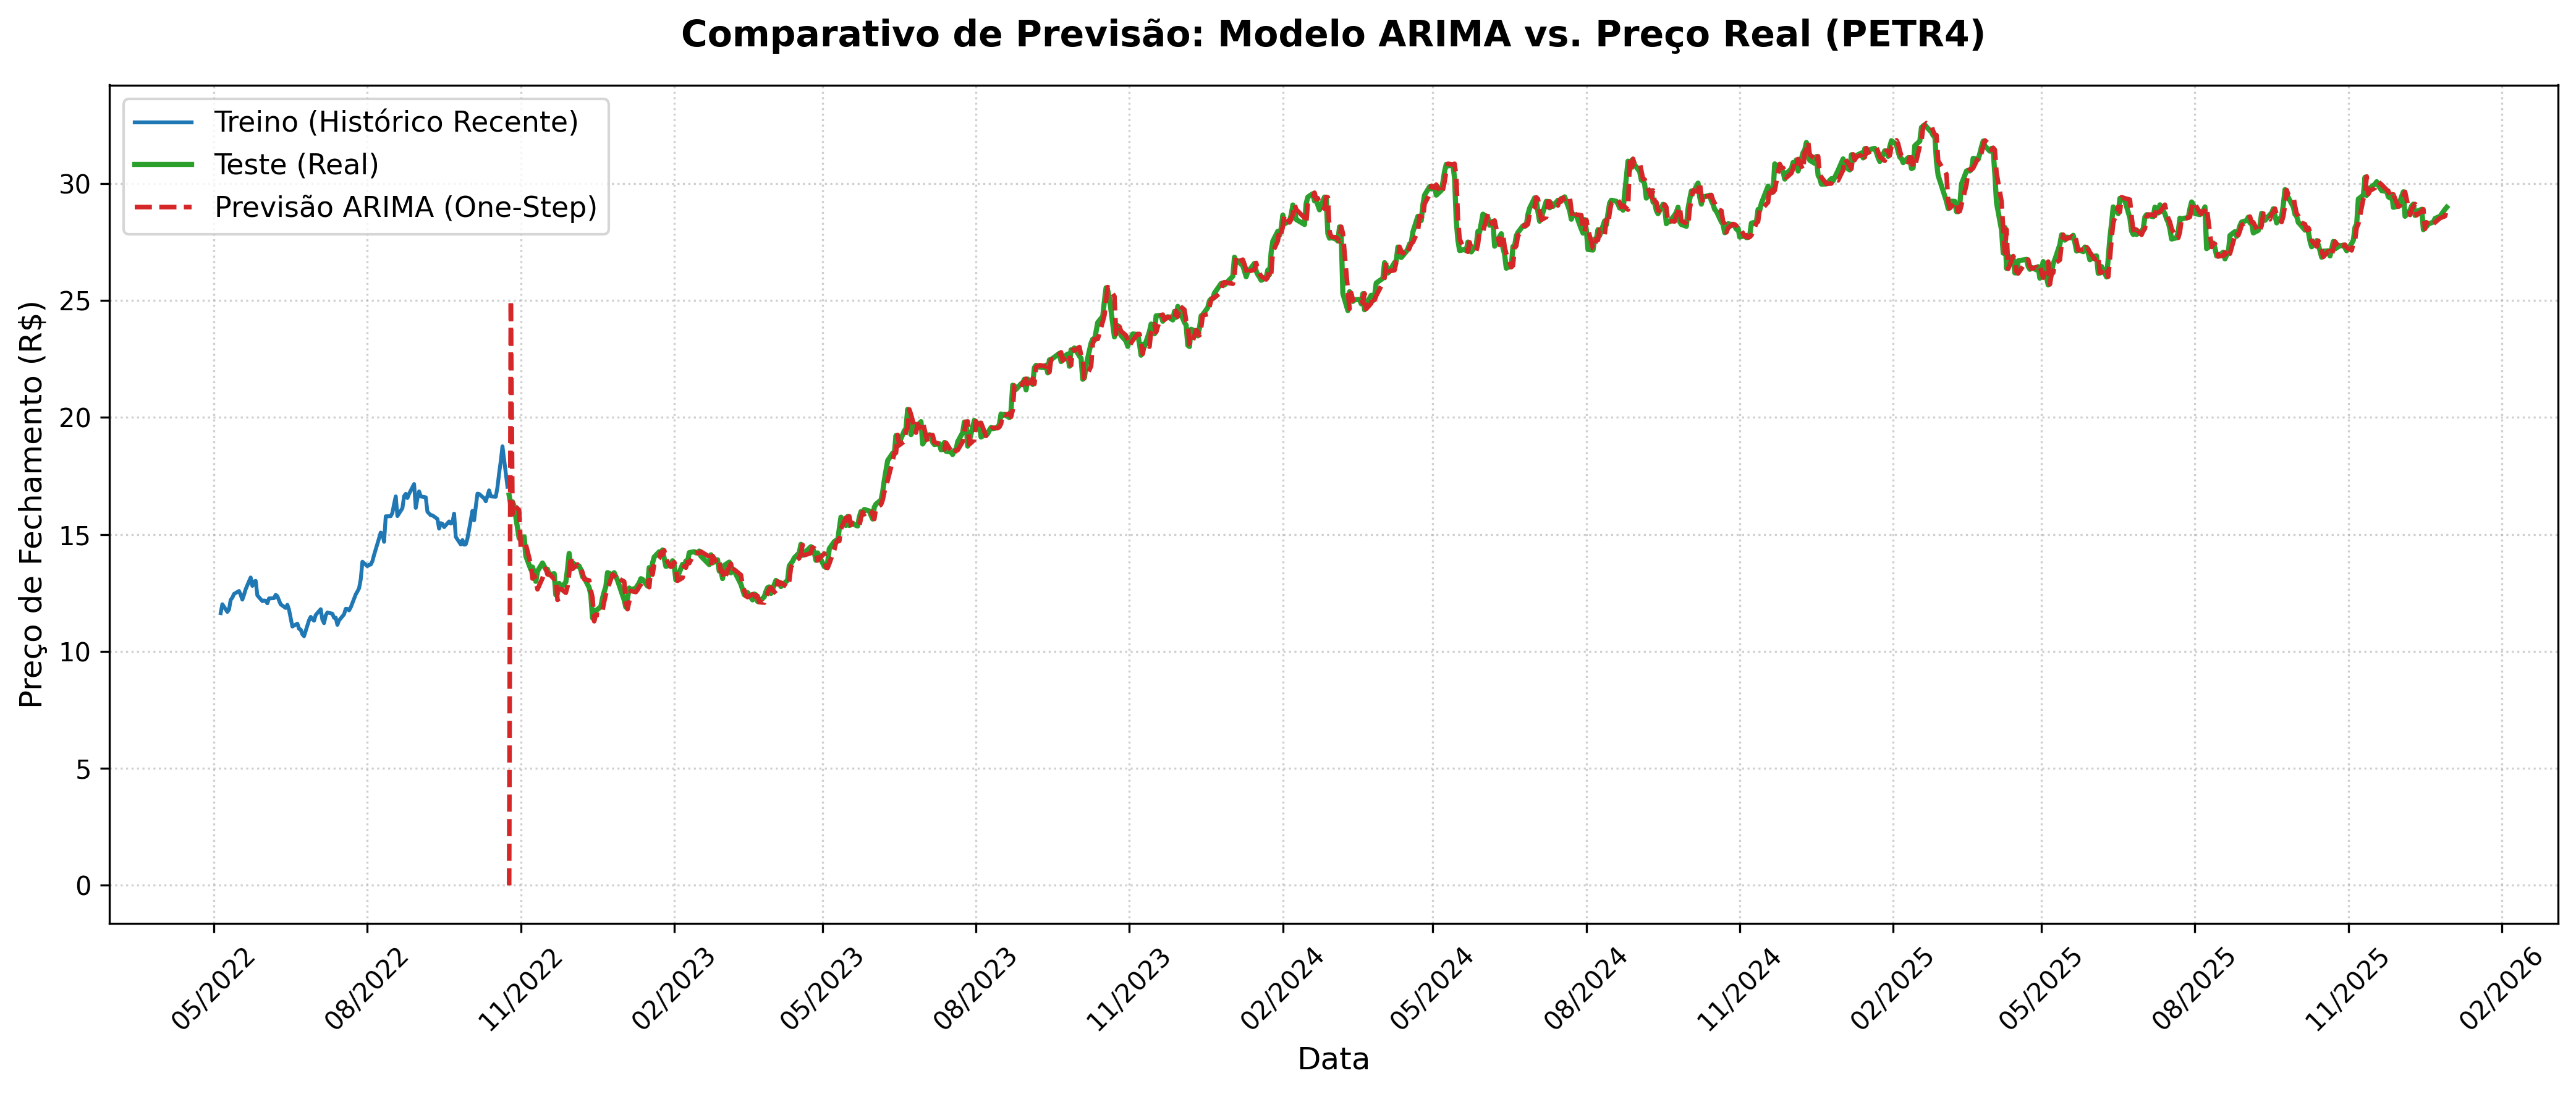

In [ ]:
# Definir o zoom: mostra apenas o final do treino para não 'apertar' a visualização do teste
zoom_treino = train_petro.iloc[-120:]  # Últimos ~6 meses de treino (120 dias úteis)

plt.figure(figsize=(14, 6), dpi=300)  # Resolução alta para exportar ao Word/LaTeX

# 1. Dados Históricos (Treino Recente e Teste Real)
plt.plot(
    zoom_treino.index,
    zoom_treino['petro_close'],
    label='Treino (Histórico Recente)',
    color='#1f77b4',
    linewidth=1.5,
)
plt.plot(
    test_petro.index,
    test_petro['petro_close'],
    label='Teste (Real)',
    color='#2ca02c',
    linewidth=2,
)

# 2. Previsão do ARIMA (Alinhada ao índice de teste)
plt.plot(
    test_petro.index,
    previsoes_arima,
    label='Previsão ARIMA (One-Step)',
    color='#d62728',
    linestyle='--',
    linewidth=1.8,
)

# 3. Formatação Acadêmica
plt.title(
    'Comparativo de Previsão: Modelo ARIMA vs. Preço Real (PETR4)',
    fontsize=14,
    pad=15,
    fontweight='bold',
)
plt.xlabel('Data', fontsize=12)
plt.ylabel('Preço de Fechamento (R$)', fontsize=12)
plt.legend(loc='upper left', fontsize=11, frameon=True)
plt.grid(True, linestyle=':', alpha=0.6)

# Melhorar a formatação das datas no eixo X
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%m/%Y'))
plt.gca().xaxis.set_major_locator(
    mdates.MonthLocator(interval=3)
)  # Marcações a cada 3 meses
plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig('grafico_arima_petro.png', dpi=300)  # Salva em alta qualidade
plt.show()

## ITUB4

In [ ]:
# --- Corte único, usado como referência pelos 3 modelos ---
train_itau, test_itau = split_temporal(dataset_itau, train_frac=0.8)
cut_date = test_itau.index[0]

In [ ]:
train_itau = train_itau.set_index(pd.to_datetime(train_itau['date'])).drop(columns=['index'], errors='ignore')
test_itau = test_itau.set_index(pd.to_datetime(test_itau['date'])).drop(columns=['index'], errors='ignore')

In [ ]:
# 1. auto_arima encontra a melhor ordem (p, d, q) no TREINO
print('--- Identificando Ordem do ARIMA Básico ---')
modelo_auto = auto_arima(
    train_itau['itau_close'],
    seasonal=False,
    trace=True,
    suppress_warnings=True,
)
ordem = modelo_auto.order
print(f'Ordem ARIMA Selecionada: {ordem}')

# 2. Treina o modelo inicial no conjunto de TREINO
modelo_treinado = ARIMA(train_itau['itau_close'], order=ordem).fit()

# 3. Walk-Forward Simulation no TESTE:
# O método .apply() estende a estrutura do modelo ao conjunto de TESTE,
# fazendo previsões de 1 passo à frente (one-step-ahead) usando os preços reais passados.
modelo_expandido = modelo_treinado.apply(test_itau['itau_close'])

# Obter as previsões ajustadas para o período de teste
previsoes_arima = modelo_expandido.fittedvalues

# 4. Avaliação justa das métricas
y_test = test_itau['itau_close']
rmse_arima = np.sqrt(mean_squared_error(y_test, previsoes_arima))
mape_arima = mean_absolute_percentage_error(y_test, previsoes_arima)

print(f'\n--- Resultados do ARIMA Básico (One-Step Ahead) ---')
print(f'RMSE: {rmse_arima:.4f}')
print(f'MAPE: {mape_arima:.2%}')

--- Identificando Ordem do ARIMA Básico ---
Performing stepwise search to minimize aic
 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=393.636, Time=12.03 sec
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=421.452, Time=0.56 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=413.347, Time=0.33 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=413.458, Time=0.55 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=420.201, Time=0.16 sec
 ARIMA(1,1,2)(0,0,0)[0] intercept   : AIC=417.210, Time=1.08 sec
 ARIMA(2,1,1)(0,0,0)[0] intercept   : AIC=417.212, Time=2.87 sec
 ARIMA(3,1,2)(0,0,0)[0] intercept   : AIC=406.893, Time=9.32 sec
 ARIMA(2,1,3)(0,0,0)[0] intercept   : AIC=395.316, Time=8.32 sec
 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=415.215, Time=0.52 sec
 ARIMA(1,1,3)(0,0,0)[0] intercept   : AIC=411.154, Time=6.56 sec
 ARIMA(3,1,1)(0,0,0)[0] intercept   : AIC=415.703, Time=7.42 sec
 ARIMA(3,1,3)(0,0,0)[0] intercept   : AIC=397.068, Time=9.66 sec
 ARIMA(2,1,2)(0,0,0)[0]             : AIC=392.441, Time=2.54 sec
 A

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)



--- Resultados do ARIMA Básico (One-Step Ahead) ---
RMSE: 0.7673
MAPE: 1.16%


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)


In [ ]:
acerto_direcional = np.mean(np.sign(y_test.diff()) == np.sign(previsoes_arima.diff()))
print(f'Acurácia direcional: {acerto_direcional:.2%}')

Acurácia direcional: 50.57%


In [ ]:
# Valores reais e previstos
y_true = test_itau['itau_close']
y_pred = previsoes_arima

# Métricas de erro
mae = mean_absolute_error(y_true, y_pred)
rmse = np.sqrt(mean_squared_error(y_true, y_pred))
mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100

print(f"MAE (Erro Médio Absoluto): {mae:.2f}")
print(f"RMSE (Raiz do Erro Quadrático Médio): {rmse:.2f}")
print(f"MAPE (Erro Percentual Absoluto Médio): {mape:.2f}%")

MAE (Erro Médio Absoluto): 0.27
RMSE (Raiz do Erro Quadrático Médio): 0.77
MAPE (Erro Percentual Absoluto Médio): 1.16%


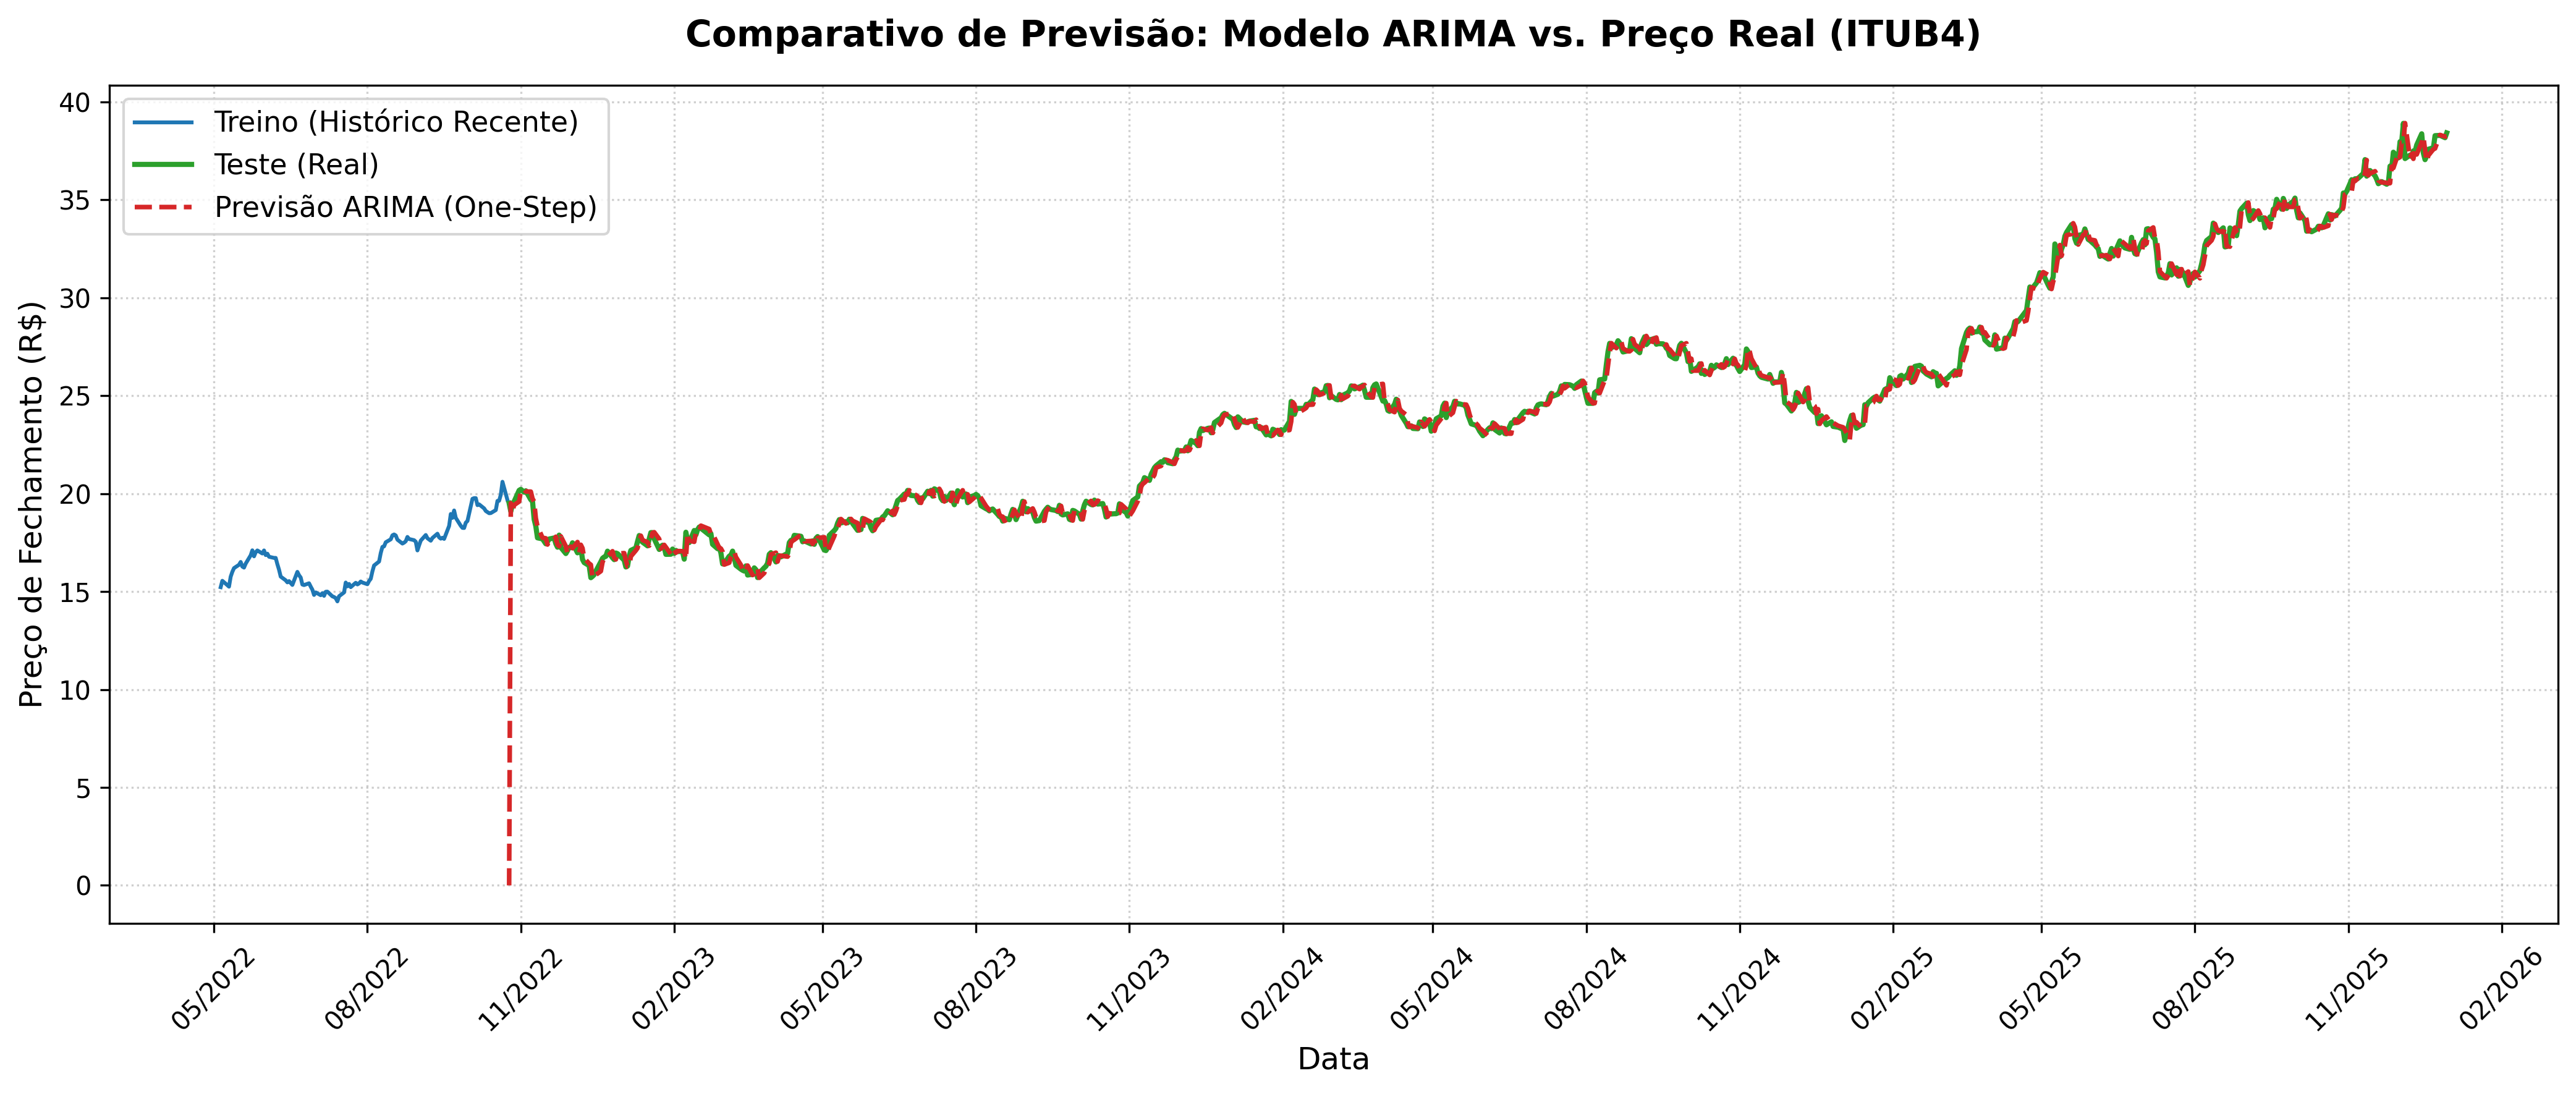

In [ ]:
# Definir o zoom: mostra apenas o final do treino para não 'apertar' a visualização do teste
zoom_treino = train_itau.iloc[-120:]  # Últimos ~6 meses de treino (120 dias úteis)

plt.figure(figsize=(14, 6), dpi=300)  # Resolução alta para exportar ao Word/LaTeX

# 1. Dados Históricos (Treino Recente e Teste Real)
plt.plot(
    zoom_treino.index,
    zoom_treino['itau_close'],
    label='Treino (Histórico Recente)',
    color='#1f77b4',
    linewidth=1.5,
)
plt.plot(
    test_itau.index,
    test_itau['itau_close'],
    label='Teste (Real)',
    color='#2ca02c',
    linewidth=2,
)

# 2. Previsão do ARIMA (Alinhada ao índice de teste)
plt.plot(
    test_itau.index,
    previsoes_arima,
    label='Previsão ARIMA (One-Step)',
    color='#d62728',
    linestyle='--',
    linewidth=1.8,
)

# 3. Formatação Acadêmica
plt.title(
    'Comparativo de Previsão: Modelo ARIMA vs. Preço Real (ITUB4)',
    fontsize=14,
    pad=15,
    fontweight='bold',
)
plt.xlabel('Data', fontsize=12)
plt.ylabel('Preço de Fechamento (R$)', fontsize=12)
plt.legend(loc='upper left', fontsize=11, frameon=True)
plt.grid(True, linestyle=':', alpha=0.6)

# Melhorar a formatação das datas no eixo X
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%m/%Y'))
plt.gca().xaxis.set_major_locator(
    mdates.MonthLocator(interval=3)
)  # Marcações a cada 3 meses
plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig('grafico_arima_itau.png', dpi=300)  # Salva em alta qualidade
plt.show()

- É possível notar que o Arima, nos casos das ações PETR4 e VALE3, consegue prever a tendência geral da variação de preço, apenas errando na previsão da ação ITUB4

# XGBoost + SHAP

In [ ]:
import xgboost as xgb
import shap

## VALE3

Total de features usadas: 28
['vale_open', 'vale_high_lag_1', 'vale_high_lag_2', 'vale_high_lag_3', 'vale_low_lag_1', 'vale_low_lag_2', 'vale_low_lag_3', 'vale_volume_lag_1', 'vale_volume_lag_2', 'vale_volume_lag_3', 'ibovespa_lag_1', 'ibovespa_lag_2', 'ibovespa_lag_3', 'vix_lag_1', 'vix_lag_2', 'vix_lag_3', 'selic_diaria_lag_1', 'selic_diaria_lag_2', 'selic_diaria_lag_3', 'selic_meta_lag_1', 'selic_meta_lag_2', 'selic_meta_lag_3', 'cambio_usd_lag_1', 'cambio_usd_lag_2', 'cambio_usd_lag_3', 'vale_close_lag_1', 'vale_close_lag_2', 'vale_close_lag_3']
Fitting 5 folds for each of 54 candidates, totalling 270 fits

--- Melhores hiperparâmetros (Vale) ---
{'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100, 'subsample': 1.0}
Melhor RMSE médio (validação): 6.2579

--- Desempenho XGBoost (Itaú) — sem vazamento, com tuning ---
RMSE: 0.8155
MAE:  0.6251
MAPE: 1.17%

--- Baseline Naive (Vale) ---
RMSE: 0.8408
MAPE: 1.14%

Acurácia direcional XGBoost: 60.25%
p-valor (teste binomial): 0.000

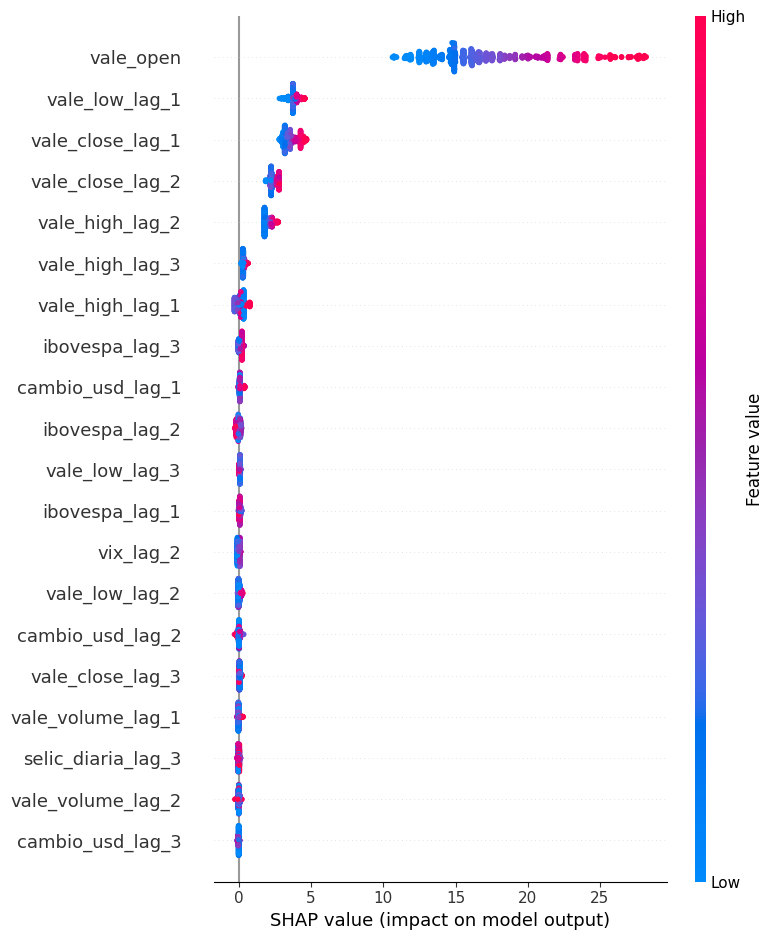

In [ ]:
# Assumindo que seu DataFrame limpo se chama 'dataset_vale'
df = dataset_vale.copy()

# 1. Definir a variável alvo e as features originais de entrada
target_col = 'vale_close'
date_col = 'date'

# Features que são conhecidas ANTES do fechamento do dia t (não precisam de lag)
features_seguras_sem_lag = ['vale_open']

# Todas as outras colunas (alta, baixa, close, volume, câmbio de fechamento etc.)
# só podem entrar defasadas — são "fechadas" junto com o alvo
features_para_lag = [
    col for col in df.columns
    if col not in [date_col, target_col] + features_seguras_sem_lag
]

# 2. Feature Engineering: Criar Lags (1, 2 e 3 dias atrás)
for feature in features_para_lag + [target_col]:
    for lag in range(1, 4):
        df[f'{feature}_lag_{lag}'] = df[feature].shift(lag)

# Tratar os valores nulos gerados pelos lags nas primeiras linhas
df = df.dropna().reset_index(drop=True)

# 3. Separar as colunas finais de treino
features_finais = features_seguras_sem_lag + [
    col for col in df.columns if '_lag_' in col
]

print(f'Total de features usadas: {len(features_finais)}')
print(features_finais)

# 4. Divisão Temporal Determinística (80% Treino / 20% Teste)
cut = int(len(df) * 0.8)
train, test = df.iloc[:cut], df.iloc[cut:]

X_train, y_train = train[features_finais], train[target_col]
X_test, y_test = test[features_finais], test[target_col]

# 5. Grid Search com validação temporal (TimeSeriesSplit) — SEM embaralhar dados
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV

tscv = TimeSeriesSplit(n_splits=5)

param_grid = {
    'n_estimators': [100, 300, 500],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.05, 0.1],
    'subsample': [0.8, 1.0],
}

grid_search = GridSearchCV(
    estimator=xgb.XGBRegressor(random_state=42),
    param_grid=param_grid,
    cv=tscv,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1,
    verbose=1,
)

grid_search.fit(X_train, y_train)

print(f'\n--- Melhores hiperparâmetros (Vale) ---')
print(grid_search.best_params_)
print(f'Melhor RMSE médio (validação): {-grid_search.best_score_:.4f}')

# 5b. Modelo final = melhor estimador encontrado (já treinado com todo X_train)
modelo_xgb = grid_search.best_estimator_

# 6. Predição no Conjunto de Teste
pred_xgb = modelo_xgb.predict(X_test)

# 7. Avaliação de Desempenho — modelo
rmse = np.sqrt(mean_squared_error(y_test, pred_xgb))
mae = mean_absolute_error(y_test, pred_xgb)
mape = mean_absolute_percentage_error(y_test, pred_xgb)

print(f'\n--- Desempenho XGBoost (Itaú) — sem vazamento, com tuning ---')
print(f'RMSE: {rmse:.4f}')
print(f'MAE:  {mae:.4f}')
print(f'MAPE: {mape:.2%}')

# 7b. Baseline naive: previsão de amanhã = close de hoje (mesma referência do ARIMA)
naive_pred = test[f'{target_col}_lag_1']

rmse_naive = np.sqrt(mean_squared_error(y_test, naive_pred))
mape_naive = mean_absolute_percentage_error(y_test, naive_pred)

print(f'\n--- Baseline Naive (Vale) ---')
print(f'RMSE: {rmse_naive:.4f}')
print(f'MAPE: {mape_naive:.2%}')

# 7c. Acurácia direcional
close_lag1_test = test[f'{target_col}_lag_1'].values
direcao_real = np.sign(y_test.values - close_lag1_test)
direcao_pred_xgb = np.sign(pred_xgb - close_lag1_test)

acerto_direcional_xgb = np.mean(direcao_real == direcao_pred_xgb)
print(f'\nAcurácia direcional XGBoost: {acerto_direcional_xgb:.2%}')

# 7d. Teste de significância (H0: acurácia = 50%)
from scipy.stats import binomtest
n = len(y_test)
acertos = int(acerto_direcional_xgb * n)
resultado_teste = binomtest(acertos, n, p=0.5, alternative='two-sided')
print(f'p-valor (teste binomial): {resultado_teste.pvalue:.4f}')

# 8. Explicabilidade com SHAP nos dados de TESTE
explainer = shap.TreeExplainer(modelo_xgb)
shap_values = explainer(X_test)

shap.summary_plot(shap_values, X_test)

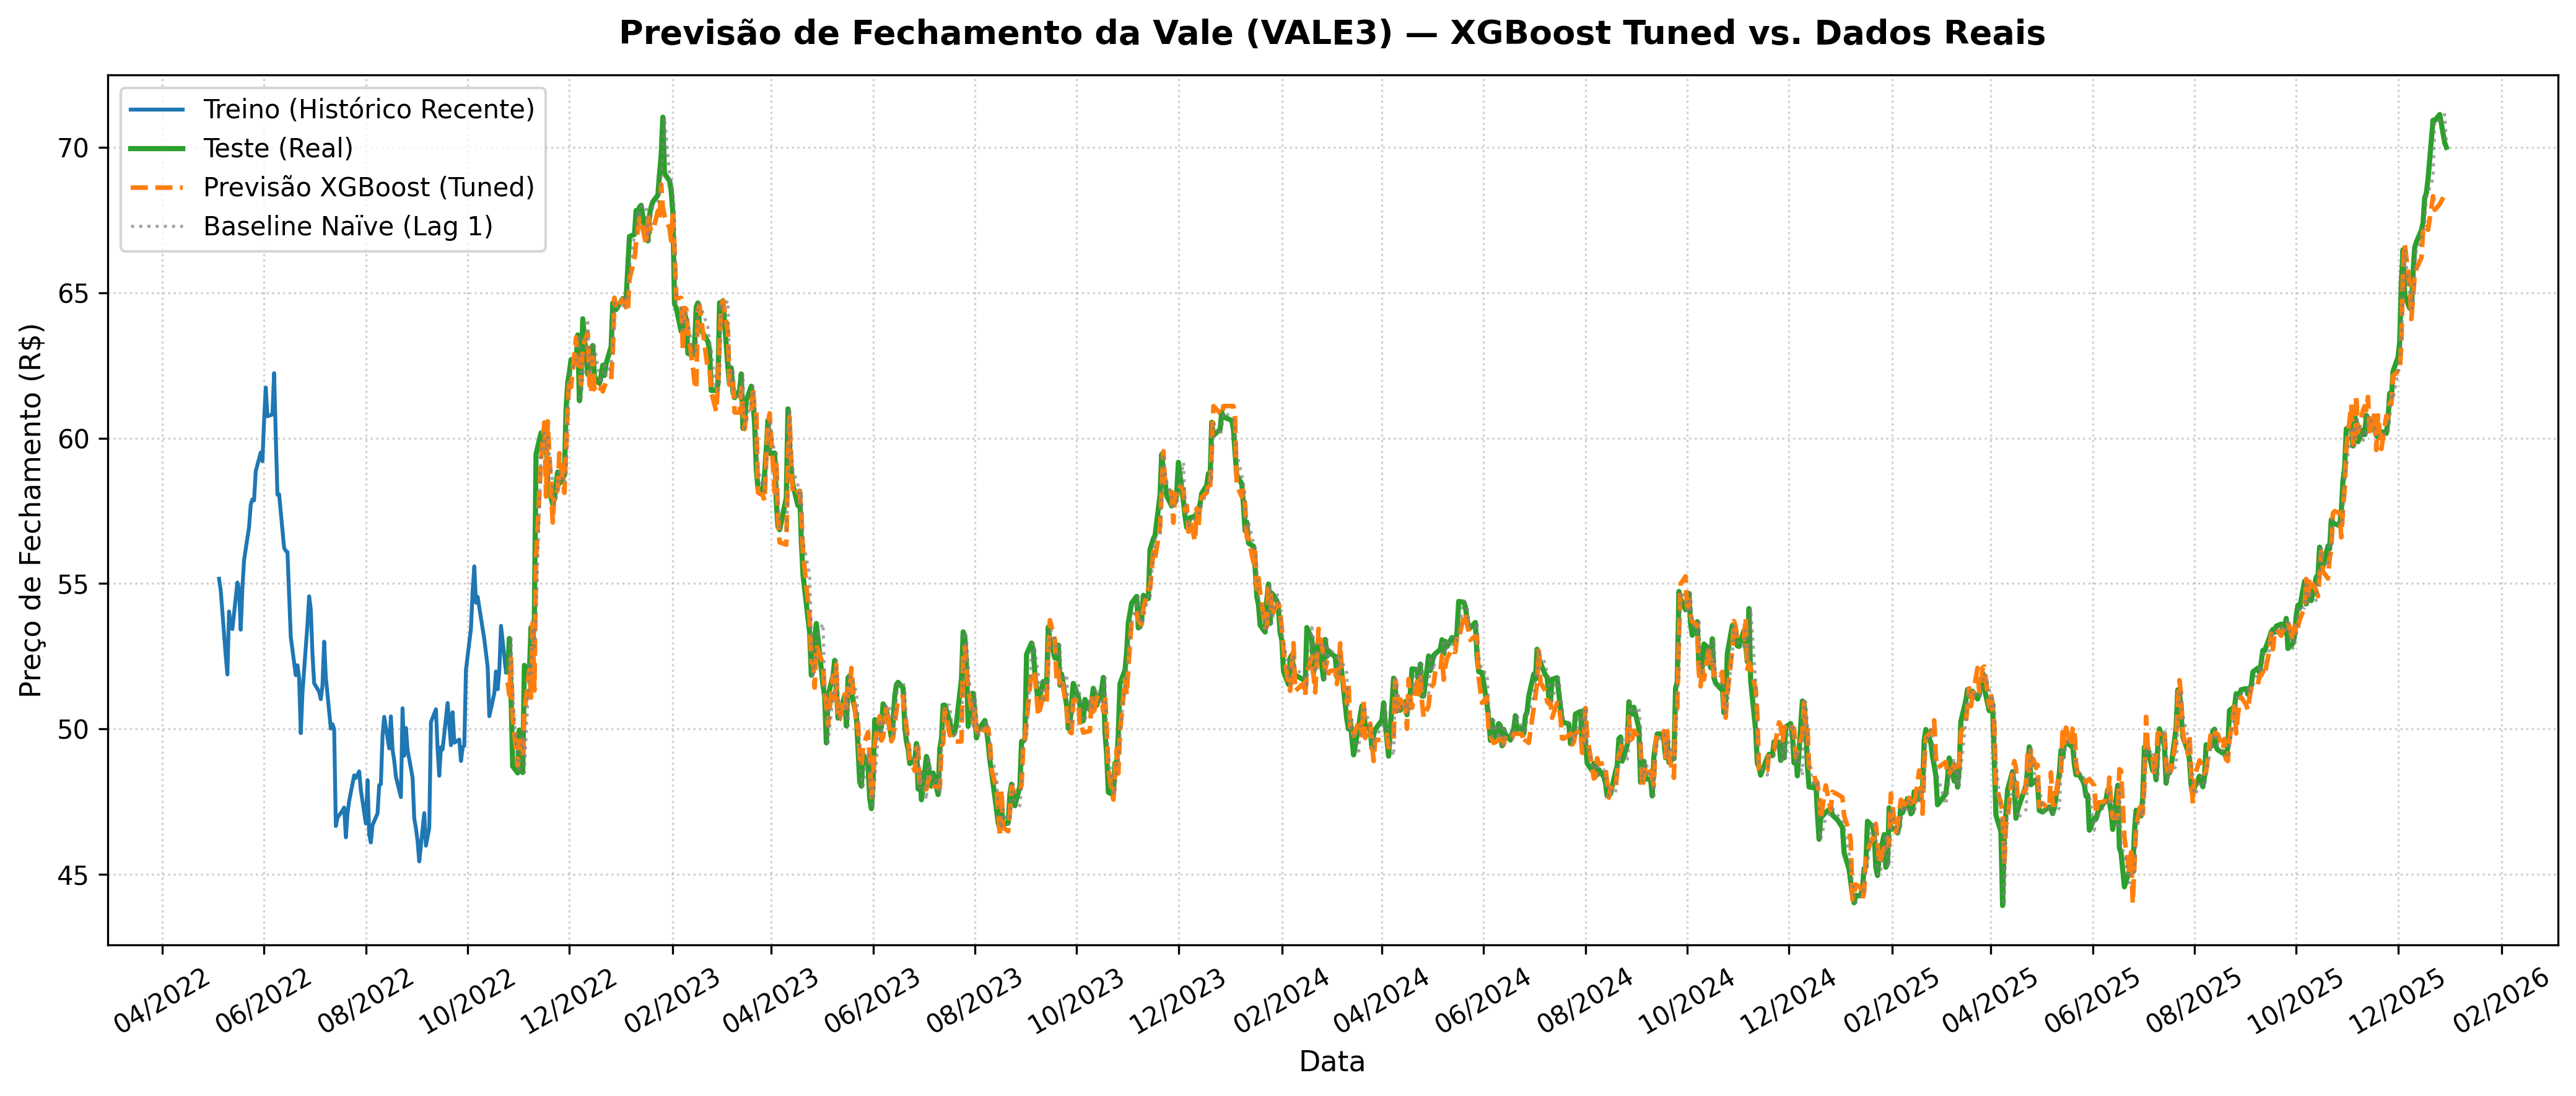

In [ ]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd

# 1. Preparação das Datas para o Eixo X
zoom_treino = train.iloc[-120:]  # Últimos 120 dias úteis (~6 meses) de treino
datas_treino = pd.to_datetime(zoom_treino[date_col])
datas_teste = pd.to_datetime(test[date_col])

# 2. Configuração da Figura e do Eixo (ax1)
fig, ax1 = plt.subplots(figsize=(14, 6), dpi=300)

# -----------------------------------------------------------------------------
# PAINEL 1: Série Temporal (Treino Recente, Teste Real, XGBoost e Naïve)
# -----------------------------------------------------------------------------
# Treino Recente
ax1.plot(
    datas_treino,
    zoom_treino[target_col],
    label='Treino (Histórico Recente)',
    color='#1f77b4',
    linewidth=1.5,
)

# Teste Real
ax1.plot(
    datas_teste,
    y_test.values,
    label='Teste (Real)',
    color='#2ca02c',
    linewidth=2.0,
)

# Previsão XGBoost (Com Tuning)
ax1.plot(
    datas_teste,
    pred_xgb,
    label='Previsão XGBoost (Tuned)',
    color='#ff7f0e',
    linestyle='--',
    linewidth=1.8,
)

# Previsão Naïve (Lag 1)
ax1.plot(
    datas_teste,
    naive_pred.values,
    label='Baseline Naïve (Lag 1)',
    color='#7f7f7f',
    linestyle=':',
    linewidth=1.2,
    alpha=0.7,
)

# Títulos e Rótulos
ax1.set_title(
    'Previsão de Fechamento da Vale (VALE3) — XGBoost Tuned vs. Dados Reais',
    fontsize=13,
    fontweight='bold',
    pad=12,
)
ax1.set_xlabel('Data', fontsize=11)
ax1.set_ylabel('Preço de Fechamento (R$)', fontsize=11)
ax1.legend(loc='upper left', fontsize=10, frameon=True, facecolor='white')
ax1.grid(True, linestyle=':', alpha=0.6)

# Formatador do Eixo X (Datas)
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%m/%Y'))
ax1.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax1.tick_params(axis='x', rotation=30)

# Ajuste Final de Layout e Salvamento
plt.tight_layout()
plt.savefig('visualizacao_xgboost_vale_tuned.png', dpi=300, bbox_inches='tight')
plt.show()

## PETR4

Total de features usadas: 28
['petro_open', 'petro_high_lag_1', 'petro_high_lag_2', 'petro_high_lag_3', 'petro_low_lag_1', 'petro_low_lag_2', 'petro_low_lag_3', 'petro_volume_lag_1', 'petro_volume_lag_2', 'petro_volume_lag_3', 'ibovespa_lag_1', 'ibovespa_lag_2', 'ibovespa_lag_3', 'vix_lag_1', 'vix_lag_2', 'vix_lag_3', 'selic_diaria_lag_1', 'selic_diaria_lag_2', 'selic_diaria_lag_3', 'selic_meta_lag_1', 'selic_meta_lag_2', 'selic_meta_lag_3', 'cambio_usd_lag_1', 'cambio_usd_lag_2', 'cambio_usd_lag_3', 'petro_close_lag_1', 'petro_close_lag_2', 'petro_close_lag_3']
Fitting 5 folds for each of 54 candidates, totalling 270 fits

--- Melhores hiperparâmetros (Petrobras) ---
{'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100, 'subsample': 1.0}
Melhor RMSE médio (validação): 0.9476

--- Desempenho XGBoost (Itaú) — sem vazamento, com tuning ---
RMSE: 10.2886
MAE:  9.0052
MAPE: 33.07%

--- Baseline Naive (Petrobras) ---
RMSE: 0.4103
MAPE: 1.30%

Acurácia direcional XGBoost: 47.80%
p-val

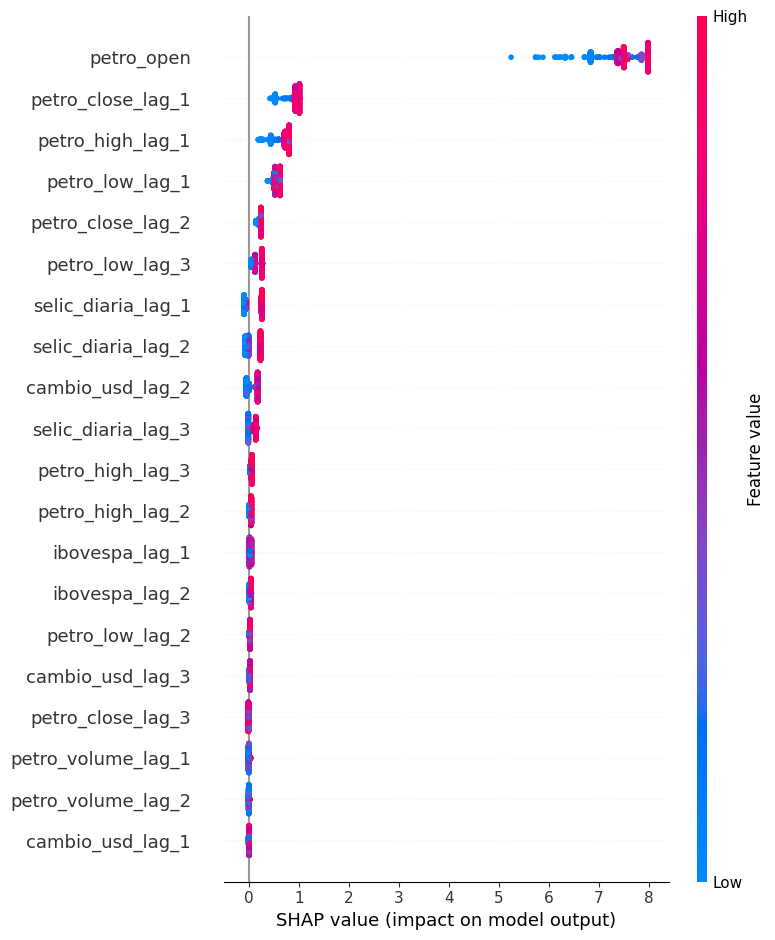

In [ ]:
# Assumindo que seu DataFrame limpo se chama 'dataset_petro'
df = dataset_petro.copy()

# 1. Definir a variável alvo e as features originais de entrada
target_col = 'petro_close'
date_col = 'date'

# Features que são conhecidas ANTES do fechamento do dia t (não precisam de lag)
features_seguras_sem_lag = ['petro_open']

# Todas as outras colunas (alta, baixa, close, volume, câmbio de fechamento etc.)
# só podem entrar defasadas — são "fechadas" junto com o alvo
features_para_lag = [
    col for col in df.columns
    if col not in [date_col, target_col] + features_seguras_sem_lag
]

# 2. Feature Engineering: Criar Lags (1, 2 e 3 dias atrás)
for feature in features_para_lag + [target_col]:
    for lag in range(1, 4):
        df[f'{feature}_lag_{lag}'] = df[feature].shift(lag)

# Tratar os valores nulos gerados pelos lags nas primeiras linhas
df = df.dropna().reset_index(drop=True)

# 3. Separar as colunas finais de treino
features_finais = features_seguras_sem_lag + [
    col for col in df.columns if '_lag_' in col
]

print(f'Total de features usadas: {len(features_finais)}')
print(features_finais)

# 4. Divisão Temporal Determinística (80% Treino / 20% Teste)
cut = int(len(df) * 0.8)
train, test = df.iloc[:cut], df.iloc[cut:]

X_train, y_train = train[features_finais], train[target_col]
X_test, y_test = test[features_finais], test[target_col]

# 5. Grid Search com validação temporal (TimeSeriesSplit) — SEM embaralhar dados
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV

tscv = TimeSeriesSplit(n_splits=5)

param_grid = {
    'n_estimators': [100, 300, 500],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.05, 0.1],
    'subsample': [0.8, 1.0],
}

grid_search = GridSearchCV(
    estimator=xgb.XGBRegressor(random_state=42),
    param_grid=param_grid,
    cv=tscv,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1,
    verbose=1,
)

grid_search.fit(X_train, y_train)

print(f'\n--- Melhores hiperparâmetros (Petrobras) ---')
print(grid_search.best_params_)
print(f'Melhor RMSE médio (validação): {-grid_search.best_score_:.4f}')

# 5b. Modelo final = melhor estimador encontrado (já treinado com todo X_train)
modelo_xgb = grid_search.best_estimator_

# 6. Predição no Conjunto de Teste
pred_xgb = modelo_xgb.predict(X_test)

# 7. Avaliação de Desempenho — modelo
rmse = np.sqrt(mean_squared_error(y_test, pred_xgb))
mae = mean_absolute_error(y_test, pred_xgb)
mape = mean_absolute_percentage_error(y_test, pred_xgb)

print(f'\n--- Desempenho XGBoost (Itaú) — sem vazamento, com tuning ---')
print(f'RMSE: {rmse:.4f}')
print(f'MAE:  {mae:.4f}')
print(f'MAPE: {mape:.2%}')

# 7b. Baseline naive: previsão de amanhã = close de hoje (mesma referência do ARIMA)
naive_pred = test[f'{target_col}_lag_1']

rmse_naive = np.sqrt(mean_squared_error(y_test, naive_pred))
mape_naive = mean_absolute_percentage_error(y_test, naive_pred)

print(f'\n--- Baseline Naive (Petrobras) ---')
print(f'RMSE: {rmse_naive:.4f}')
print(f'MAPE: {mape_naive:.2%}')

# 7c. Acurácia direcional
close_lag1_test = test[f'{target_col}_lag_1'].values
direcao_real = np.sign(y_test.values - close_lag1_test)
direcao_pred_xgb = np.sign(pred_xgb - close_lag1_test)

acerto_direcional_xgb = np.mean(direcao_real == direcao_pred_xgb)
print(f'\nAcurácia direcional XGBoost: {acerto_direcional_xgb:.2%}')

# 7d. Teste de significância (H0: acurácia = 50%)
from scipy.stats import binomtest
n = len(y_test)
acertos = int(acerto_direcional_xgb * n)
resultado_teste = binomtest(acertos, n, p=0.5, alternative='two-sided')
print(f'p-valor (teste binomial): {resultado_teste.pvalue:.4f}')

# 8. Explicabilidade com SHAP nos dados de TESTE
explainer = shap.TreeExplainer(modelo_xgb)
shap_values = explainer(X_test)

shap.summary_plot(shap_values, X_test)

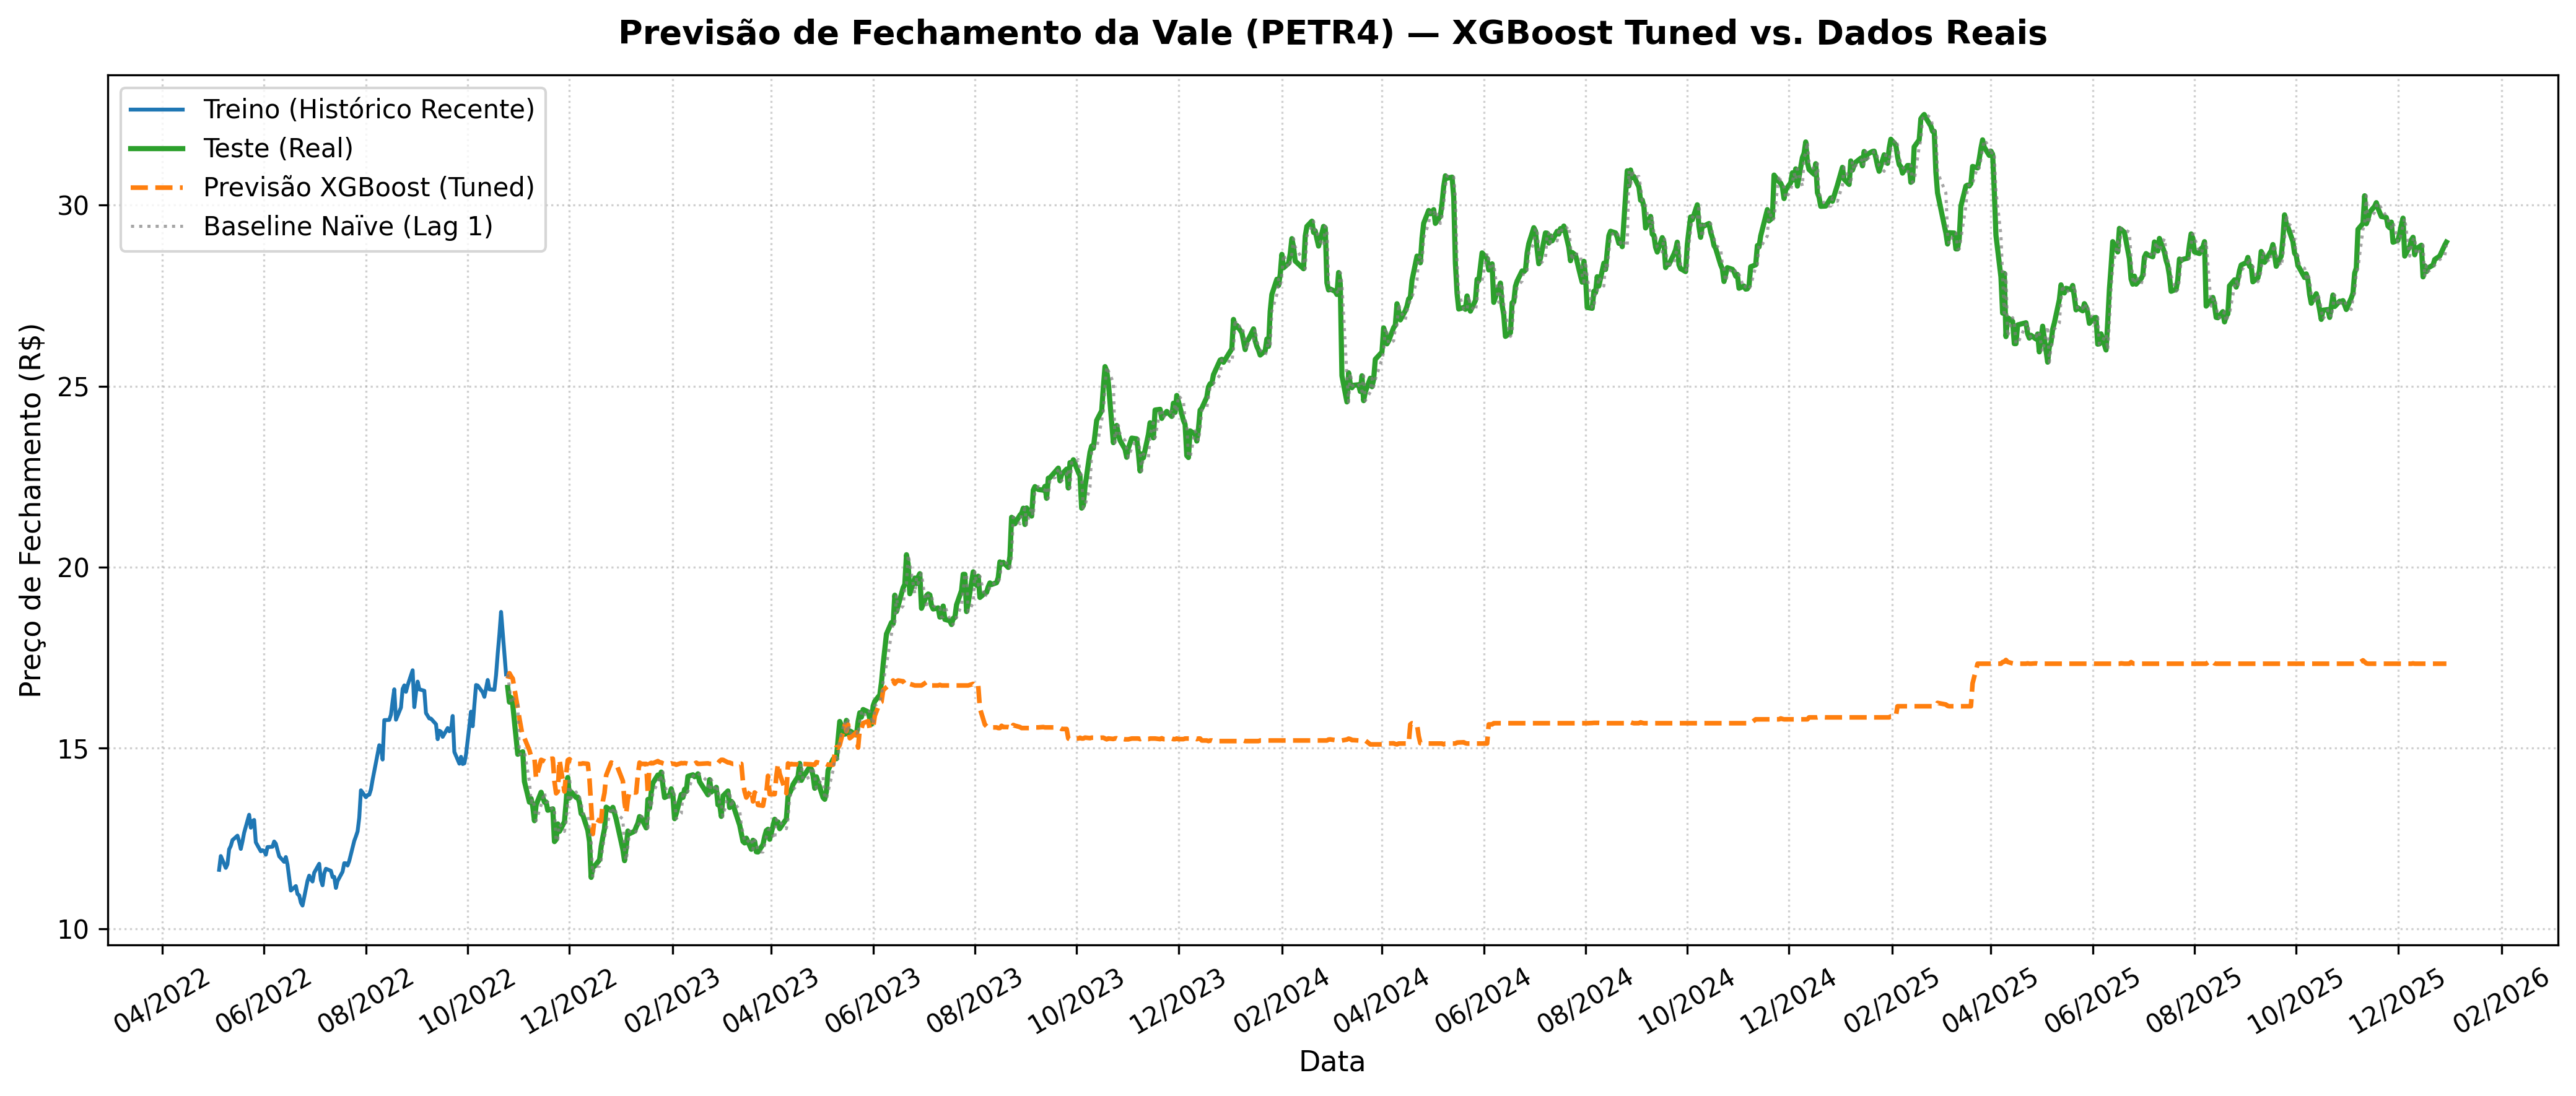

In [ ]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd

# 1. Preparação das Datas para o Eixo X
zoom_treino = train.iloc[-120:]  # Últimos 120 dias úteis (~6 meses) de treino
datas_treino = pd.to_datetime(zoom_treino[date_col])
datas_teste = pd.to_datetime(test[date_col])

# 2. Configuração da Figura e do Eixo (ax1)
fig, ax1 = plt.subplots(figsize=(14, 6), dpi=300)

# -----------------------------------------------------------------------------
# PAINEL 1: Série Temporal (Treino Recente, Teste Real, XGBoost e Naïve)
# -----------------------------------------------------------------------------
# Treino Recente
ax1.plot(
    datas_treino,
    zoom_treino[target_col],
    label='Treino (Histórico Recente)',
    color='#1f77b4',
    linewidth=1.5,
)

# Teste Real
ax1.plot(
    datas_teste,
    y_test.values,
    label='Teste (Real)',
    color='#2ca02c',
    linewidth=2.0,
)

# Previsão XGBoost (Com Tuning)
ax1.plot(
    datas_teste,
    pred_xgb,
    label='Previsão XGBoost (Tuned)',
    color='#ff7f0e',
    linestyle='--',
    linewidth=1.8,
)

# Previsão Naïve (Lag 1)
ax1.plot(
    datas_teste,
    naive_pred.values,
    label='Baseline Naïve (Lag 1)',
    color='#7f7f7f',
    linestyle=':',
    linewidth=1.2,
    alpha=0.7,
)

# Títulos e Rótulos
ax1.set_title(
    'Previsão de Fechamento da Vale (PETR4) — XGBoost Tuned vs. Dados Reais',
    fontsize=13,
    fontweight='bold',
    pad=12,
)
ax1.set_xlabel('Data', fontsize=11)
ax1.set_ylabel('Preço de Fechamento (R$)', fontsize=11)
ax1.legend(loc='upper left', fontsize=10, frameon=True, facecolor='white')
ax1.grid(True, linestyle=':', alpha=0.6)

# Formatador do Eixo X (Datas)
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%m/%Y'))
ax1.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax1.tick_params(axis='x', rotation=30)

# Ajuste Final de Layout e Salvamento
plt.tight_layout()
plt.savefig('visualizacao_xgboost_vale_tuned.png', dpi=300, bbox_inches='tight')
plt.show()

## ITUB4

Total de features usadas: 28
['itau_open', 'itau_high_lag_1', 'itau_high_lag_2', 'itau_high_lag_3', 'itau_low_lag_1', 'itau_low_lag_2', 'itau_low_lag_3', 'itau_volume_lag_1', 'itau_volume_lag_2', 'itau_volume_lag_3', 'ibovespa_lag_1', 'ibovespa_lag_2', 'ibovespa_lag_3', 'vix_lag_1', 'vix_lag_2', 'vix_lag_3', 'selic_diaria_lag_1', 'selic_diaria_lag_2', 'selic_diaria_lag_3', 'selic_meta_lag_1', 'selic_meta_lag_2', 'selic_meta_lag_3', 'cambio_usd_lag_1', 'cambio_usd_lag_2', 'cambio_usd_lag_3', 'itau_close_lag_1', 'itau_close_lag_2', 'itau_close_lag_3']
Fitting 5 folds for each of 54 candidates, totalling 270 fits

--- Melhores hiperparâmetros (Itaú) ---
{'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100, 'subsample': 0.8}
Melhor RMSE médio (validação): 1.5371

--- Desempenho XGBoost (Itaú) — sem vazamento, com tuning ---
RMSE: 6.0017
MAE:  3.9713
MAPE: 13.06%

--- Baseline Naive (Itaú) ---
RMSE: 0.3297
MAPE: 1.02%

Acurácia direcional XGBoost: 49.94%
p-valor (teste binomial): 1.00

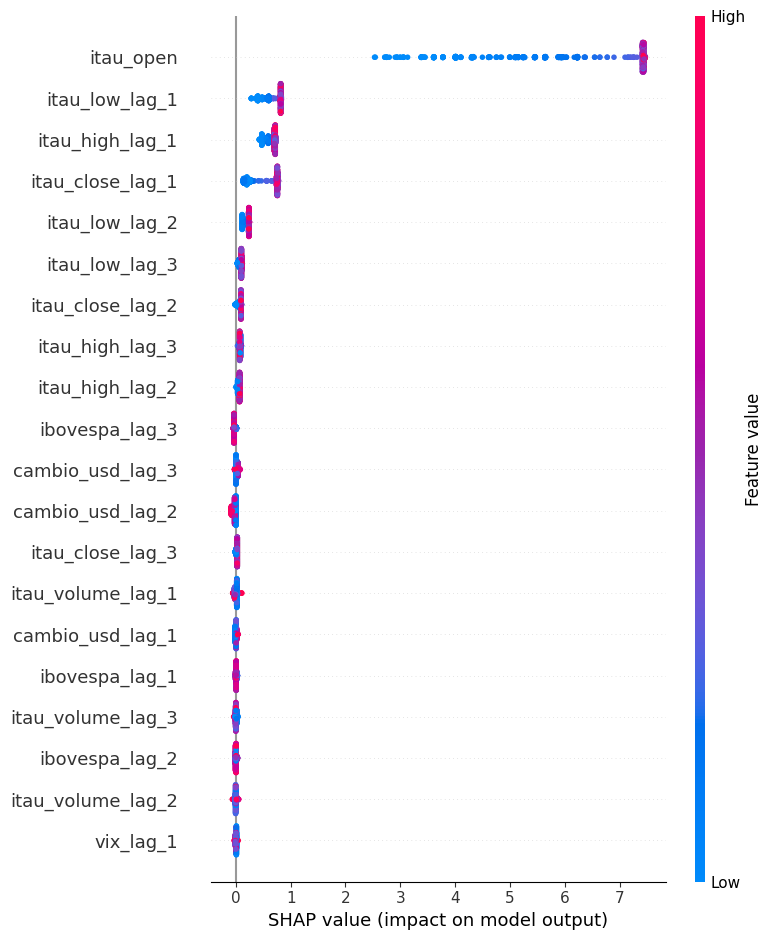

In [ ]:
# Assumindo que seu DataFrame limpo se chama 'dataset_vale'
df = dataset_itau.copy()

# 1. Definir a variável alvo e as features originais de entrada
target_col = 'itau_close'
date_col = 'date'

# Features que são conhecidas ANTES do fechamento do dia t (não precisam de lag)
features_seguras_sem_lag = ['itau_open']

# Todas as outras colunas (alta, baixa, close, volume, câmbio de fechamento etc.)
# só podem entrar defasadas — são "fechadas" junto com o alvo
features_para_lag = [
    col for col in df.columns
    if col not in [date_col, target_col] + features_seguras_sem_lag
]

# 2. Feature Engineering: Criar Lags (1, 2 e 3 dias atrás)
for feature in features_para_lag + [target_col]:
    for lag in range(1, 4):
        df[f'{feature}_lag_{lag}'] = df[feature].shift(lag)

# Tratar os valores nulos gerados pelos lags nas primeiras linhas
df = df.dropna().reset_index(drop=True)

# 3. Separar as colunas finais de treino
features_finais = features_seguras_sem_lag + [
    col for col in df.columns if '_lag_' in col
]

print(f'Total de features usadas: {len(features_finais)}')
print(features_finais)

# 4. Divisão Temporal Determinística (80% Treino / 20% Teste)
cut = int(len(df) * 0.8)
train, test = df.iloc[:cut], df.iloc[cut:]

X_train, y_train = train[features_finais], train[target_col]
X_test, y_test = test[features_finais], test[target_col]

# 5. Grid Search com validação temporal (TimeSeriesSplit) — SEM embaralhar dados
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV

tscv = TimeSeriesSplit(n_splits=5)

param_grid = {
    'n_estimators': [100, 300, 500],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.05, 0.1],
    'subsample': [0.8, 1.0],
}

grid_search = GridSearchCV(
    estimator=xgb.XGBRegressor(random_state=42),
    param_grid=param_grid,
    cv=tscv,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1,
    verbose=1,
)

grid_search.fit(X_train, y_train)

print(f'\n--- Melhores hiperparâmetros (Itaú) ---')
print(grid_search.best_params_)
print(f'Melhor RMSE médio (validação): {-grid_search.best_score_:.4f}')

# 5b. Modelo final = melhor estimador encontrado (já treinado com todo X_train)
modelo_xgb = grid_search.best_estimator_

# 6. Predição no Conjunto de Teste
pred_xgb = modelo_xgb.predict(X_test)

# 7. Avaliação de Desempenho — modelo
rmse = np.sqrt(mean_squared_error(y_test, pred_xgb))
mae = mean_absolute_error(y_test, pred_xgb)
mape = mean_absolute_percentage_error(y_test, pred_xgb)

print(f'\n--- Desempenho XGBoost (Itaú) — sem vazamento, com tuning ---')
print(f'RMSE: {rmse:.4f}')
print(f'MAE:  {mae:.4f}')
print(f'MAPE: {mape:.2%}')

# 7b. Baseline naive: previsão de amanhã = close de hoje (mesma referência do ARIMA)
naive_pred = test[f'{target_col}_lag_1']

rmse_naive = np.sqrt(mean_squared_error(y_test, naive_pred))
mape_naive = mean_absolute_percentage_error(y_test, naive_pred)

print(f'\n--- Baseline Naive (Itaú) ---')
print(f'RMSE: {rmse_naive:.4f}')
print(f'MAPE: {mape_naive:.2%}')

# 7c. Acurácia direcional
close_lag1_test = test[f'{target_col}_lag_1'].values
direcao_real = np.sign(y_test.values - close_lag1_test)
direcao_pred_xgb = np.sign(pred_xgb - close_lag1_test)

acerto_direcional_xgb = np.mean(direcao_real == direcao_pred_xgb)
print(f'\nAcurácia direcional XGBoost: {acerto_direcional_xgb:.2%}')

# 7d. Teste de significância (H0: acurácia = 50%)
from scipy.stats import binomtest
n = len(y_test)
acertos = int(acerto_direcional_xgb * n)
resultado_teste = binomtest(acertos, n, p=0.5, alternative='two-sided')
print(f'p-valor (teste binomial): {resultado_teste.pvalue:.4f}')

# 8. Explicabilidade com SHAP nos dados de TESTE
explainer = shap.TreeExplainer(modelo_xgb)
shap_values = explainer(X_test)

shap.summary_plot(shap_values, X_test)

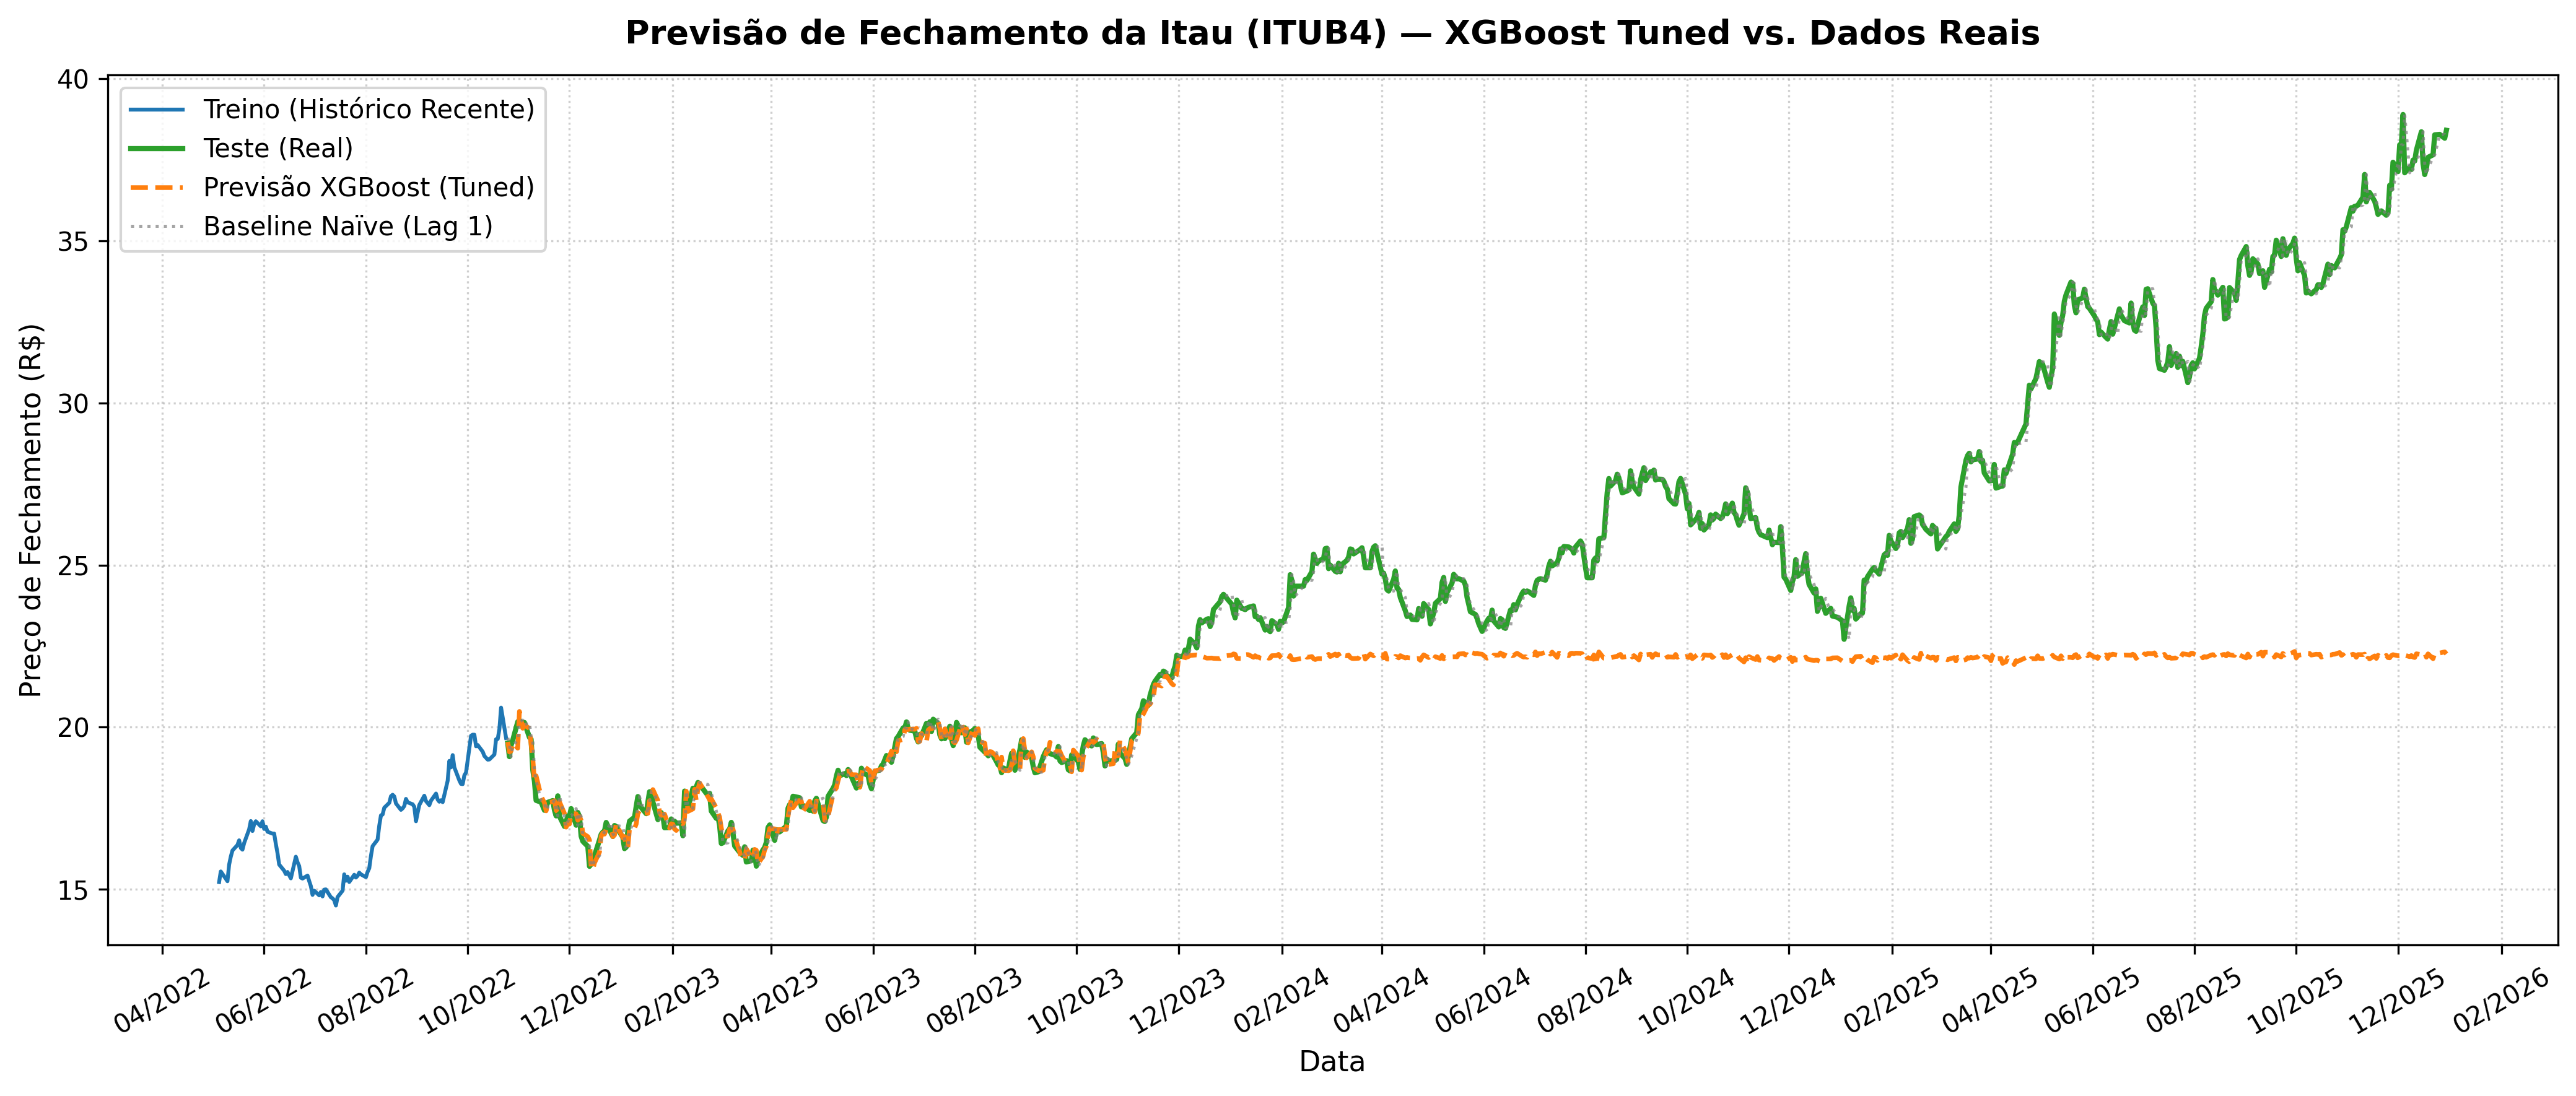

In [ ]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd

# 1. Preparação das Datas alinhadas com o conjunto filtrado
zoom_treino = train.iloc[-120:]  # Últimos 120 dias úteis de treino
datas_treino = pd.to_datetime(zoom_treino['date'])

# Ajuste: Garantir que datas_teste tenha exatamente a mesma quantidade de linhas do teste filtrado
datas_teste = pd.to_datetime(test['date'])

# 2. Configuração da Figura e do Eixo (ax1)
fig, ax1 = plt.subplots(figsize=(14, 6), dpi=300)

# -----------------------------------------------------------------------------
# PAINEL 1: Série Temporal (Treino Recente, Teste Real, XGBoost e Naïve)
# -----------------------------------------------------------------------------
# Treino Recente
ax1.plot(
    datas_treino,
    zoom_treino['itau_close'],
    label='Treino (Histórico Recente)',
    color='#1f77b4',
    linewidth=1.5,
)

# Teste Real
ax1.plot(
    datas_teste,
    y_test,  # Usando o vetor alinhado de 794 elementos
    label='Teste (Real)',
    color='#2ca02c',
    linewidth=2.0,
)

# Previsão XGBoost (Reconstruída dos Retornos)
ax1.plot(
    datas_teste,
    pred_xgb,  # Usando o preço reconstruído (794 elementos)
    label='Previsão XGBoost (Tuned)',
    color='#ff7f0e',
    linestyle='--',
    linewidth=1.8,
)

# Previsão Naïve (Lag 1 em R$)
ax1.plot(
    datas_teste,
    naive_pred.values,  # Usando o lag em R$ (794 elementos)
    label='Baseline Naïve (Lag 1)',
    color='#7f7f7f',
    linestyle=':',
    linewidth=1.2,
    alpha=0.7,
)

# Títulos e Rótulos
ax1.set_title(
    'Previsão de Fechamento da Itau (ITUB4) — XGBoost Tuned vs. Dados Reais',
    fontsize=13,
    fontweight='bold',
    pad=12,
)
ax1.set_xlabel('Data', fontsize=11)
ax1.set_ylabel('Preço de Fechamento (R$)', fontsize=11)
ax1.legend(loc='upper left', fontsize=10, frameon=True, facecolor='white')
ax1.grid(True, linestyle=':', alpha=0.6)

# Formatador do Eixo X (Datas)
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%m/%Y'))
ax1.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax1.tick_params(axis='x', rotation=30)

# Ajuste Final de Layout e Salvamento
plt.tight_layout()
plt.savefig('visualizacao_xgboost_itau_tuned.png', dpi=300, bbox_inches='tight')
plt.show()

# LSTM

In [ ]:
!pip install keras-tuner --quiet

In [ ]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping

import keras_tuner as kt

## VALE3

In [ ]:
print(dataset_vale.columns.tolist())
print(dataset_vale.shape)
print(dataset_vale.index.min(), dataset_vale.index.max())

['date', 'vale_close', 'vale_high', 'vale_low', 'vale_open', 'vale_volume', 'ibovespa', 'vix', 'selic_diaria', 'selic_meta', 'cambio_usd']
(3974, 11)
0 3973


In [ ]:
!pip install keras-tuner --quiet

import numpy as np
import pandas as pd
import tensorflow as tf
import keras_tuner as kt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
import matplotlib.pyplot as plt

# --- 1. Preparação dos dados ---
df = dataset_vale.copy().sort_index()

target_col = "vale_close"

# pega só colunas numéricas — exclui datas/objetos que possam ter sobrado
feature_cols = df.select_dtypes(include=[np.number]).columns.tolist()

# garante que a data não é uma coluna solta (se for, ela some daqui,
# mas continua acessível via df.index)
assert not np.issubdtype(df.index.dtype, np.datetime64) or True  # índice de data é ok, não entra em feature_cols

# --- 2. Split temporal (sem embaralhar) ---
n = len(df)
test_start = int(n * 0.80)          # mesmo corte 80/20 do ARIMA
val_start = int(test_start * 0.85)   # validação = últimos 15% DO TREINO (não da série toda)

train_df = df.iloc[:val_start]
val_df = df.iloc[val_start:test_start]
test_df = df.iloc[test_start:]

print(f"Treino: {train_df.shape}, Validação: {val_df.shape}, Teste: {test_df.shape}")

# --- 3. Normalização (fit só no treino) ---
scaler_x = MinMaxScaler()
scaler_y = MinMaxScaler()

train_x_scaled = scaler_x.fit_transform(train_df[feature_cols])
val_x_scaled = scaler_x.transform(val_df[feature_cols])
test_x_scaled = scaler_x.transform(test_df[feature_cols])

train_y_scaled = scaler_y.fit_transform(train_df[[target_col]])
val_y_scaled = scaler_y.transform(val_df[[target_col]])
test_y_scaled = scaler_y.transform(test_df[[target_col]])

# --- 4. Janelas temporais ---
def cria_janelas(x, y, janela):
    X, Y = [], []
    for i in range(janela, len(x)):
        X.append(x[i-janela:i])
        Y.append(y[i])
    return np.array(X), np.array(Y)

JANELA = 20

X_train, y_train = cria_janelas(train_x_scaled, train_y_scaled, JANELA)
X_val, y_val = cria_janelas(val_x_scaled, val_y_scaled, JANELA)
X_test, y_test = cria_janelas(test_x_scaled, test_y_scaled, JANELA)

print(X_train.shape, X_val.shape, X_test.shape)

# --- 5. Modelo parametrizado pro Keras Tuner ---
def build_model(hp):
    model = tf.keras.Sequential()
    n_layers = hp.Int("n_layers", 1, 3)
    for i in range(n_layers):
        units = hp.Int(f"units_{i}", min_value=32, max_value=256, step=32)
        return_seq = i < n_layers - 1
        if i == 0:
            model.add(tf.keras.layers.LSTM(
                units, return_sequences=return_seq,
                input_shape=(X_train.shape[1], X_train.shape[2])
            ))
        else:
            model.add(tf.keras.layers.LSTM(units, return_sequences=return_seq))
        model.add(tf.keras.layers.Dropout(hp.Float(f"dropout_{i}", 0.0, 0.5, step=0.1)))
    model.add(tf.keras.layers.Dense(1))

    lr = hp.Choice("learning_rate", [1e-2, 1e-3, 1e-4])
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
                  loss="mse", metrics=["mae"])
    return model

# --- 6. Busca de hiperparâmetros ---
tuner = kt.Hyperband(
    build_model,
    objective="val_loss",
    max_epochs=50,
    factor=3,
    directory="lstm_tuning",
    project_name="vale3_fechamento_v1.1"
)

early_stop = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

tuner.search(X_train, y_train, validation_data=(X_val, y_val),
             epochs=50, callbacks=[early_stop], verbose=1)

# --- 7. Melhor modelo ---
best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]
print("Melhores hiperparâmetros:")
for param, valor in best_hps.values.items():
    print(f"  {param}: {valor}")

melhor_modelo = tuner.hypermodel.build(best_hps)
historico = melhor_modelo.fit(X_train, y_train, validation_data=(X_val, y_val),
                               epochs=100, callbacks=[early_stop], verbose=1)

Trial 90 Complete [00h 01m 19s]
val_loss: 0.007376589346677065

Best val_loss So Far: 0.0020448954310268164
Total elapsed time: 01h 37m 18s
Melhores hiperparâmetros:
  n_layers: 1
  units_0: 224
  dropout_0: 0.0
  learning_rate: 0.001
  units_1: 128
  dropout_1: 0.4
  units_2: 192
  dropout_2: 0.1
  tuner/epochs: 50
  tuner/initial_epoch: 17
  tuner/bracket: 2
  tuner/round: 2
  tuner/trial_id: 0067
Epoch 1/100
84/84 ━━━━━━━━━━━━━━━━━━━━ 7s 52ms/step - loss: 0.0079 - mae: 0.0481 - val_loss: 0.0589 - val_mae: 0.2246
Epoch 2/100
84/84 ━━━━━━━━━━━━━━━━━━━━ 4s 45ms/step - loss: 5.5253e-04 - mae: 0.0173 - val_loss: 0.0204 - val_mae: 0.1248
Epoch 3/100
84/84 ━━━━━━━━━━━━━━━━━━━━ 5s 56ms/step - loss: 4.4160e-04 - mae: 0.0155 - val_loss: 0.0103 - val_mae: 0.0844
Epoch 4/100
84/84 ━━━━━━━━━━━━━━━━━━━━ 4s 48ms/step - loss: 4.2554e-04 - mae: 0.0152 - val_loss: 0.0086 - val_mae: 0.0764
Epoch 5/100
84/84 ━━━━━━━━━━━━━━━━━━━━ 5s 46ms/step - loss: 3.9400e-04 - mae: 0.0148 - val_loss: 0.0137 - val_mae

25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step
RMSE (em R$): 1.1654
MAE (em R$): 0.8976

Baseline Naïve — RMSE: 0.7979, MAE: 0.5873

Acurácia direcional LSTM (preço): 48.58%
p-valor (teste binomial): 0.4504


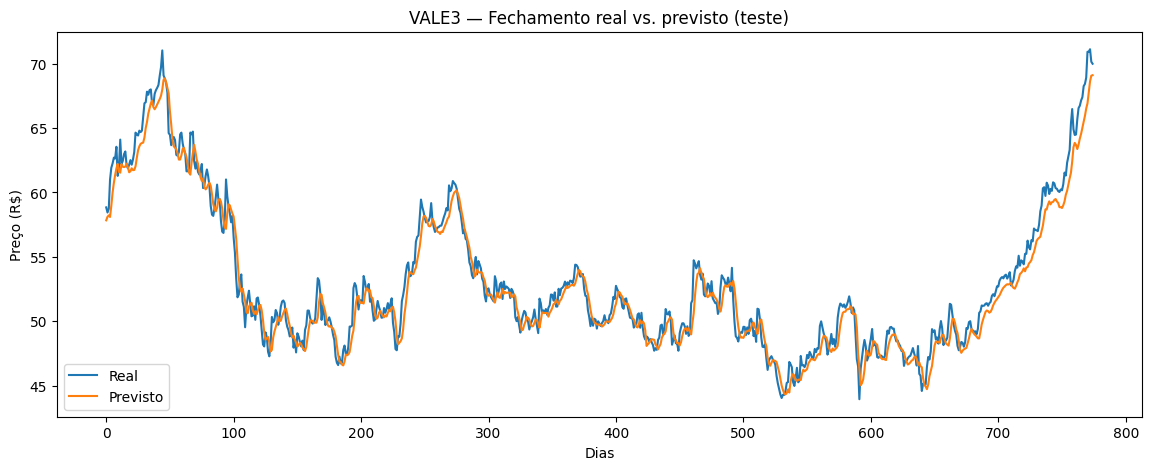

In [ ]:
# --- 8. Avaliação (o modelo já prevê PREÇO diretamente) ---
pred_scaled = melhor_modelo.predict(X_test)
pred_preco = scaler_y.inverse_transform(pred_scaled).flatten()
real_preco = scaler_y.inverse_transform(y_test).flatten()

rmse = np.sqrt(mean_squared_error(real_preco, pred_preco))
mae = mean_absolute_error(real_preco, pred_preco)
print(f"RMSE (em R$): {rmse:.4f}")
print(f"MAE (em R$): {mae:.4f}")

# --- Baseline Naïve (preço de amanhã = preço de hoje) ---
# "hoje" = preço real do dia anterior dentro do próprio teste
preco_base_teste = real_preco[:-1]
real_amanha = real_preco[1:]
pred_amanha = pred_preco[1:]

rmse_naive = np.sqrt(mean_squared_error(real_amanha, preco_base_teste))
mae_naive = mean_absolute_error(real_amanha, preco_base_teste)
print(f"\nBaseline Naïve — RMSE: {rmse_naive:.4f}, MAE: {mae_naive:.4f}")

# --- 8b. Acurácia direcional ---
from scipy.stats import binomtest

direcao_real = np.sign(real_amanha - preco_base_teste)
direcao_pred = np.sign(pred_amanha - preco_base_teste)

acerto_direcional = np.mean(direcao_real == direcao_pred)
print(f"\nAcurácia direcional LSTM (preço): {acerto_direcional:.2%}")

n = len(direcao_real)
acertos = int(acerto_direcional * n)
resultado_teste = binomtest(acertos, n, p=0.5, alternative='two-sided')
print(f"p-valor (teste binomial): {resultado_teste.pvalue:.4f}")

# --- 9. Gráfico ---
plt.figure(figsize=(14, 5))
plt.plot(real_preco, label="Real")
plt.plot(pred_preco, label="Previsto")
plt.title("VALE3 — Fechamento real vs. previsto (teste)")
plt.xlabel("Dias")
plt.ylabel("Preço (R$)")
plt.legend()
plt.show()

## PETR4

In [ ]:
!pip install keras-tuner --quiet

import numpy as np
import pandas as pd
import tensorflow as tf
import keras_tuner as kt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
import matplotlib.pyplot as plt

# --- 1. Preparação dos dados ---
df = dataset_petro.copy().sort_index()

target_col = "petro_close"

# pega só colunas numéricas — exclui datas/objetos que possam ter sobrado
feature_cols = df.select_dtypes(include=[np.number]).columns.tolist()

# garante que a data não é uma coluna solta (se for, ela some daqui,
# mas continua acessível via df.index)
assert not np.issubdtype(df.index.dtype, np.datetime64) or True  # índice de data é ok, não entra em feature_cols

# --- 2. Split temporal (sem embaralhar) ---
n = len(df)
test_start = int(n * 0.80)          # mesmo corte 80/20 do ARIMA
val_start = int(test_start * 0.85)   # validação = últimos 15% DO TREINO (não da série toda)

train_df = df.iloc[:val_start]
val_df = df.iloc[val_start:test_start]
test_df = df.iloc[test_start:]

print(f"Treino: {train_df.shape}, Validação: {val_df.shape}, Teste: {test_df.shape}")

# --- 3. Normalização (fit só no treino) ---
scaler_x = MinMaxScaler()
scaler_y = MinMaxScaler()

train_x_scaled = scaler_x.fit_transform(train_df[feature_cols])
val_x_scaled = scaler_x.transform(val_df[feature_cols])
test_x_scaled = scaler_x.transform(test_df[feature_cols])

train_y_scaled = scaler_y.fit_transform(train_df[[target_col]])
val_y_scaled = scaler_y.transform(val_df[[target_col]])
test_y_scaled = scaler_y.transform(test_df[[target_col]])

# --- 4. Janelas temporais ---
def cria_janelas(x, y, janela):
    X, Y = [], []
    for i in range(janela, len(x)):
        X.append(x[i-janela:i])
        Y.append(y[i])
    return np.array(X), np.array(Y)

JANELA = 20

X_train, y_train = cria_janelas(train_x_scaled, train_y_scaled, JANELA)
X_val, y_val = cria_janelas(val_x_scaled, val_y_scaled, JANELA)
X_test, y_test = cria_janelas(test_x_scaled, test_y_scaled, JANELA)

print(X_train.shape, X_val.shape, X_test.shape)

# --- 5. Modelo parametrizado pro Keras Tuner ---
def build_model(hp):
    model = tf.keras.Sequential()
    n_layers = hp.Int("n_layers", 1, 3)
    for i in range(n_layers):
        units = hp.Int(f"units_{i}", min_value=32, max_value=256, step=32)
        return_seq = i < n_layers - 1
        if i == 0:
            model.add(tf.keras.layers.LSTM(
                units, return_sequences=return_seq,
                input_shape=(X_train.shape[1], X_train.shape[2])
            ))
        else:
            model.add(tf.keras.layers.LSTM(units, return_sequences=return_seq))
        model.add(tf.keras.layers.Dropout(hp.Float(f"dropout_{i}", 0.0, 0.5, step=0.1)))
    model.add(tf.keras.layers.Dense(1))

    lr = hp.Choice("learning_rate", [1e-2, 1e-3, 1e-4])
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
                  loss="mse", metrics=["mae"])
    return model

# --- 6. Busca de hiperparâmetros ---
tuner = kt.Hyperband(
    build_model,
    objective="val_loss",
    max_epochs=50,
    factor=3,
    directory="lstm_tuning",
    project_name="petr4_fechamento_v1"
)

early_stop = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

tuner.search(X_train, y_train, validation_data=(X_val, y_val),
             epochs=50, callbacks=[early_stop], verbose=1)

# --- 7. Melhor modelo ---
best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]
print("Melhores hiperparâmetros:")
for param, valor in best_hps.values.items():
    print(f"  {param}: {valor}")

melhor_modelo = tuner.hypermodel.build(best_hps)
historico = melhor_modelo.fit(X_train, y_train, validation_data=(X_val, y_val),
                               epochs=100, callbacks=[early_stop], verbose=1)

Trial 90 Complete [00h 02m 28s]
val_loss: 0.15147247910499573

Best val_loss So Far: 0.0016246861778199673
Total elapsed time: 02h 58m 42s
Melhores hiperparâmetros:
  n_layers: 1
  units_0: 256
  dropout_0: 0.0
  learning_rate: 0.001
  units_1: 160
  dropout_1: 0.30000000000000004
  units_2: 64
  dropout_2: 0.2
  tuner/epochs: 50
  tuner/initial_epoch: 17
  tuner/bracket: 1
  tuner/round: 1
  tuner/trial_id: 0078
Epoch 1/100
84/84 ━━━━━━━━━━━━━━━━━━━━ 8s 73ms/step - loss: 0.0112 - mae: 0.0546 - val_loss: 0.0247 - val_mae: 0.1101
Epoch 2/100
84/84 ━━━━━━━━━━━━━━━━━━━━ 5s 58ms/step - loss: 0.0010 - mae: 0.0218 - val_loss: 0.0128 - val_mae: 0.0778
Epoch 3/100
84/84 ━━━━━━━━━━━━━━━━━━━━ 7s 76ms/step - loss: 8.7487e-04 - mae: 0.0206 - val_loss: 0.0098 - val_mae: 0.0701
Epoch 4/100
84/84 ━━━━━━━━━━━━━━━━━━━━ 9s 67ms/step - loss: 7.5480e-04 - mae: 0.0194 - val_loss: 0.0044 - val_mae: 0.0467
Epoch 5/100
84/84 ━━━━━━━━━━━━━━━━━━━━ 10s 59ms/step - loss: 7.0078e-04 - mae: 0.0189 - val_loss: 0.007

25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step
RMSE (em R$): 0.7726
MAE (em R$): 0.6339

Baseline Naïve — RMSE: 0.4082, MAE: 0.2945

Acurácia direcional LSTM (preço): 49.22%
p-valor (teste binomial): 0.6926


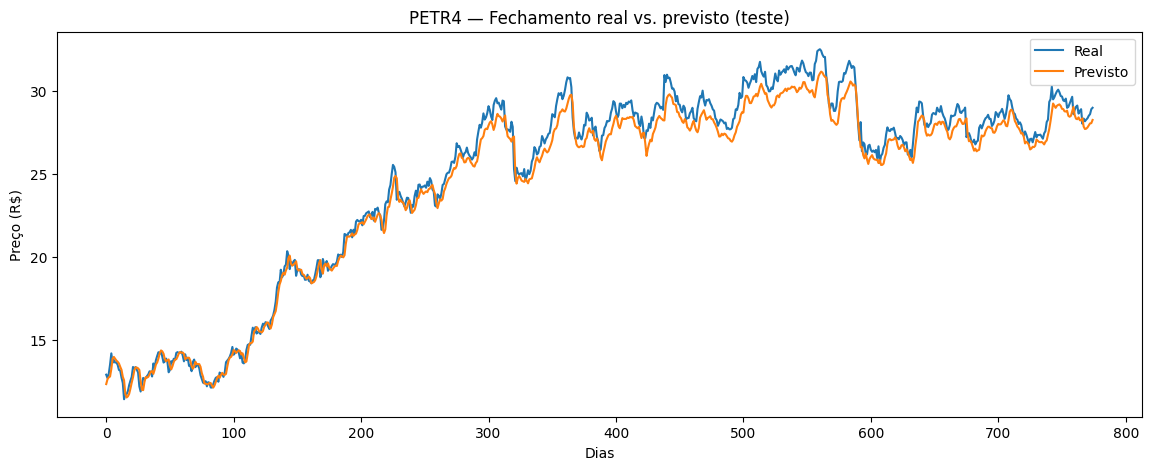

In [ ]:
# --- 8. Avaliação (o modelo já prevê PREÇO diretamente) ---
pred_scaled = melhor_modelo.predict(X_test)
pred_preco = scaler_y.inverse_transform(pred_scaled).flatten()
real_preco = scaler_y.inverse_transform(y_test).flatten()

rmse = np.sqrt(mean_squared_error(real_preco, pred_preco))
mae = mean_absolute_error(real_preco, pred_preco)
print(f"RMSE (em R$): {rmse:.4f}")
print(f"MAE (em R$): {mae:.4f}")

# --- Baseline Naïve (preço de amanhã = preço de hoje) ---
# "hoje" = preço real do dia anterior dentro do próprio teste
preco_base_teste = real_preco[:-1]
real_amanha = real_preco[1:]
pred_amanha = pred_preco[1:]

rmse_naive = np.sqrt(mean_squared_error(real_amanha, preco_base_teste))
mae_naive = mean_absolute_error(real_amanha, preco_base_teste)
print(f"\nBaseline Naïve — RMSE: {rmse_naive:.4f}, MAE: {mae_naive:.4f}")

# --- 8b. Acurácia direcional ---
from scipy.stats import binomtest

direcao_real = np.sign(real_amanha - preco_base_teste)
direcao_pred = np.sign(pred_amanha - preco_base_teste)

acerto_direcional = np.mean(direcao_real == direcao_pred)
print(f"\nAcurácia direcional LSTM (preço): {acerto_direcional:.2%}")

n = len(direcao_real)
acertos = int(acerto_direcional * n)
resultado_teste = binomtest(acertos, n, p=0.5, alternative='two-sided')
print(f"p-valor (teste binomial): {resultado_teste.pvalue:.4f}")

# --- 9. Gráfico ---
plt.figure(figsize=(14, 5))
plt.plot(real_preco, label="Real")
plt.plot(pred_preco, label="Previsto")
plt.title("PETR4 — Fechamento real vs. previsto (teste)")
plt.xlabel("Dias")
plt.ylabel("Preço (R$)")
plt.legend()
plt.show()

## ITUB4

In [ ]:
!pip install keras-tuner --quiet

import numpy as np
import pandas as pd
import tensorflow as tf
import keras_tuner as kt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
import matplotlib.pyplot as plt

# --- 1. Preparação dos dados ---
df = dataset_itau.copy().sort_index()

target_col = "itau_close"

# pega só colunas numéricas — exclui datas/objetos que possam ter sobrado
feature_cols = df.select_dtypes(include=[np.number]).columns.tolist()

# garante que a data não é uma coluna solta (se for, ela some daqui,
# mas continua acessível via df.index)
assert not np.issubdtype(df.index.dtype, np.datetime64) or True  # índice de data é ok, não entra em feature_cols

# --- 2. Split temporal (sem embaralhar) ---
n = len(df)
test_start = int(n * 0.80)          # mesmo corte 80/20 do ARIMA
val_start = int(test_start * 0.85)   # validação = últimos 15% DO TREINO (não da série toda)

train_df = df.iloc[:val_start]
val_df = df.iloc[val_start:test_start]
test_df = df.iloc[test_start:]

print(f"Treino: {train_df.shape}, Validação: {val_df.shape}, Teste: {test_df.shape}")

# --- 3. Normalização (fit só no treino) ---
scaler_x = MinMaxScaler()
scaler_y = MinMaxScaler()

train_x_scaled = scaler_x.fit_transform(train_df[feature_cols])
val_x_scaled = scaler_x.transform(val_df[feature_cols])
test_x_scaled = scaler_x.transform(test_df[feature_cols])

train_y_scaled = scaler_y.fit_transform(train_df[[target_col]])
val_y_scaled = scaler_y.transform(val_df[[target_col]])
test_y_scaled = scaler_y.transform(test_df[[target_col]])

# --- 4. Janelas temporais ---
def cria_janelas(x, y, janela):
    X, Y = [], []
    for i in range(janela, len(x)):
        X.append(x[i-janela:i])
        Y.append(y[i])
    return np.array(X), np.array(Y)

JANELA = 20

X_train, y_train = cria_janelas(train_x_scaled, train_y_scaled, JANELA)
X_val, y_val = cria_janelas(val_x_scaled, val_y_scaled, JANELA)
X_test, y_test = cria_janelas(test_x_scaled, test_y_scaled, JANELA)

print(X_train.shape, X_val.shape, X_test.shape)

# --- 5. Modelo parametrizado pro Keras Tuner ---
def build_model(hp):
    model = tf.keras.Sequential()
    n_layers = hp.Int("n_layers", 1, 3)
    for i in range(n_layers):
        units = hp.Int(f"units_{i}", min_value=32, max_value=256, step=32)
        return_seq = i < n_layers - 1
        if i == 0:
            model.add(tf.keras.layers.LSTM(
                units, return_sequences=return_seq,
                input_shape=(X_train.shape[1], X_train.shape[2])
            ))
        else:
            model.add(tf.keras.layers.LSTM(units, return_sequences=return_seq))
        model.add(tf.keras.layers.Dropout(hp.Float(f"dropout_{i}", 0.0, 0.5, step=0.1)))
    model.add(tf.keras.layers.Dense(1))

    lr = hp.Choice("learning_rate", [1e-2, 1e-3, 1e-4])
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
                  loss="mse", metrics=["mae"])
    return model

# --- 6. Busca de hiperparâmetros ---
tuner = kt.Hyperband(
    build_model,
    objective="val_loss",
    max_epochs=50,
    factor=3,
    directory="lstm_tuning",
    project_name="itub4_fechamento"
)

early_stop = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

tuner.search(X_train, y_train, validation_data=(X_val, y_val),
             epochs=50, callbacks=[early_stop], verbose=1)

# --- 7. Melhor modelo ---
best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]
print("Melhores hiperparâmetros:")
for param, valor in best_hps.values.items():
    print(f"  {param}: {valor}")

melhor_modelo = tuner.hypermodel.build(best_hps)
historico = melhor_modelo.fit(X_train, y_train, validation_data=(X_val, y_val),
                               epochs=100, callbacks=[early_stop], verbose=1)

Trial 90 Complete [00h 05m 24s]
val_loss: 0.0013556239427998662

Best val_loss So Far: 0.00038949758163653314
Total elapsed time: 01h 27m 38s
Melhores hiperparâmetros:
  n_layers: 1
  units_0: 224
  dropout_0: 0.0
  learning_rate: 0.001
  units_1: 96
  dropout_1: 0.2
  units_2: 64
  dropout_2: 0.4
  tuner/epochs: 50
  tuner/initial_epoch: 17
  tuner/bracket: 2
  tuner/round: 2
  tuner/trial_id: 0069
Epoch 1/100
84/84 ━━━━━━━━━━━━━━━━━━━━ 6s 47ms/step - loss: 0.0052 - mae: 0.0397 - val_loss: 0.0018 - val_mae: 0.0346
Epoch 2/100
84/84 ━━━━━━━━━━━━━━━━━━━━ 5s 61ms/step - loss: 5.4558e-04 - mae: 0.0168 - val_loss: 9.4465e-04 - val_mae: 0.0241
Epoch 3/100
84/84 ━━━━━━━━━━━━━━━━━━━━ 4s 44ms/step - loss: 4.6004e-04 - mae: 0.0153 - val_loss: 0.0012 - val_mae: 0.0278
Epoch 4/100
84/84 ━━━━━━━━━━━━━━━━━━━━ 4s 44ms/step - loss: 4.8426e-04 - mae: 0.0160 - val_loss: 8.5309e-04 - val_mae: 0.0226
Epoch 5/100
84/84 ━━━━━━━━━━━━━━━━━━━━ 5s 62ms/step - loss: 4.0719e-04 - mae: 0.0144 - val_loss: 7.0725e-

25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step
RMSE (em R$): 0.4503
MAE (em R$): 0.3459

Baseline Naïve — RMSE: 0.3286, MAE: 0.2456

Acurácia direcional LSTM (preço): 48.19%
p-valor (teste binomial): 0.3318


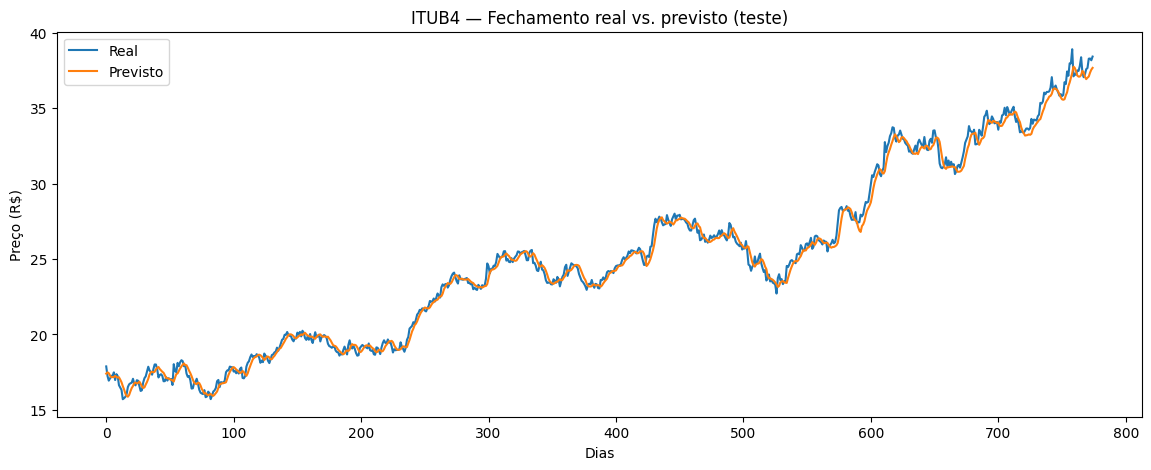

In [ ]:
# --- 8. Avaliação (o modelo já prevê PREÇO diretamente) ---
pred_scaled = melhor_modelo.predict(X_test)
pred_preco = scaler_y.inverse_transform(pred_scaled).flatten()
real_preco = scaler_y.inverse_transform(y_test).flatten()

rmse = np.sqrt(mean_squared_error(real_preco, pred_preco))
mae = mean_absolute_error(real_preco, pred_preco)
print(f"RMSE (em R$): {rmse:.4f}")
print(f"MAE (em R$): {mae:.4f}")

# --- Baseline Naïve (preço de amanhã = preço de hoje) ---
# "hoje" = preço real do dia anterior dentro do próprio teste
preco_base_teste = real_preco[:-1]
real_amanha = real_preco[1:]
pred_amanha = pred_preco[1:]

rmse_naive = np.sqrt(mean_squared_error(real_amanha, preco_base_teste))
mae_naive = mean_absolute_error(real_amanha, preco_base_teste)
print(f"\nBaseline Naïve — RMSE: {rmse_naive:.4f}, MAE: {mae_naive:.4f}")

# --- 8b. Acurácia direcional ---
from scipy.stats import binomtest

direcao_real = np.sign(real_amanha - preco_base_teste)
direcao_pred = np.sign(pred_amanha - preco_base_teste)

acerto_direcional = np.mean(direcao_real == direcao_pred)
print(f"\nAcurácia direcional LSTM (preço): {acerto_direcional:.2%}")

n = len(direcao_real)
acertos = int(acerto_direcional * n)
resultado_teste = binomtest(acertos, n, p=0.5, alternative='two-sided')
print(f"p-valor (teste binomial): {resultado_teste.pvalue:.4f}")

# --- 9. Gráfico ---
plt.figure(figsize=(14, 5))
plt.plot(real_preco, label="Real")
plt.plot(pred_preco, label="Previsto")
plt.title("ITUB4 — Fechamento real vs. previsto (teste)")
plt.xlabel("Dias")
plt.ylabel("Preço (R$)")
plt.legend()
plt.show()

# Previsão geral